In [1]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')


    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [2]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, cohen_kappa_score
from sklearn.model_selection import cross_val_score
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import LabelEncoder

In [3]:
class MLP_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """MLP para extrair features + GRU para capturar dependências"""

    def __init__(self,
                 mlp_hidden_layers=(32, 16),
                 mlp_dropout=0.2,
                 gru_hidden=32,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(16,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.mlp_hidden_layers = mlp_hidden_layers
        self.mlp_dropout = mlp_dropout
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class MLP_GRU_Model(nn.Module):
            def __init__(self, input_size, mlp_hiddens, mlp_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(MLP_GRU_Model, self).__init__()

                # MLP para transformar features
                mlp_layers = []
                prev_size = input_size

                for hidden in mlp_hiddens:
                    mlp_layers.append(nn.Linear(prev_size, hidden))
                    mlp_layers.append(nn.ReLU())
                    mlp_layers.append(nn.Dropout(mlp_dropout))
                    prev_size = hidden

                self.mlp = nn.Sequential(*mlp_layers)

                # GRU
                self.gru = nn.GRU(
                    input_size=prev_size,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected final
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(mlp_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                # MLP
                x = self.mlp(x)

                # Reshape para GRU
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)

                # GRU
                gru_out, hidden = self.gru(x)
                last_hidden = hidden[-1]

                # Dropout e FC
                x = self.gru_dropout(last_hidden)
                x = self.fc(x)
                return x

        return MLP_GRU_Model(
            input_size=self.input_size,
            mlp_hiddens=self.mlp_hidden_layers,
            mlp_dropout=self.mlp_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

           # if (epoch + 1) % 20 == 0:
                #print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'mlp_hidden_layers': self.mlp_hidden_layers,
            'mlp_dropout': self.mlp_dropout,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_1145/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_rmsprop
------------------------------
TRAIN
Accuracy: 0.6357
Precision: 0.6086
Recall: 0.6357
F1: 0.6173
Kappa: 0.5555
Error Rate: 0.3643

TEST
Accuracy: 0.1940
Precision: 0.1469
Recall: 0.1940
F1: 0.1135
Kappa: 0.0083
Error Rate: 0.8060
Gap (overfitting): 0.4417

CV
Mean: 0.6443
Std: 0.0462
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



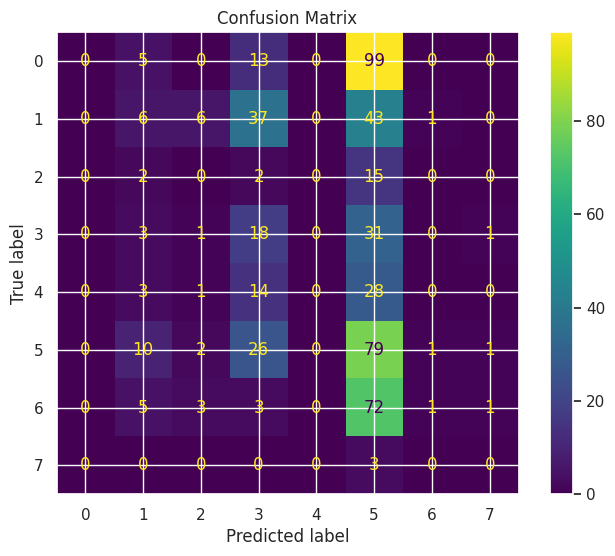

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_adam
------------------------------
TRAIN
Accuracy: 0.6053
Precision: 0.5806
Recall: 0.6053
F1: 0.5739
Kappa: 0.5152
Error Rate: 0.3947

TEST
Accuracy: 0.1922
Precision: 0.1986
Recall: 0.1922
F1: 0.1059
Kappa: 0.0021
Error Rate: 0.8078
Gap (overfitting): 0.4131

CV
Mean: 0.6190
Std: 0.0728
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



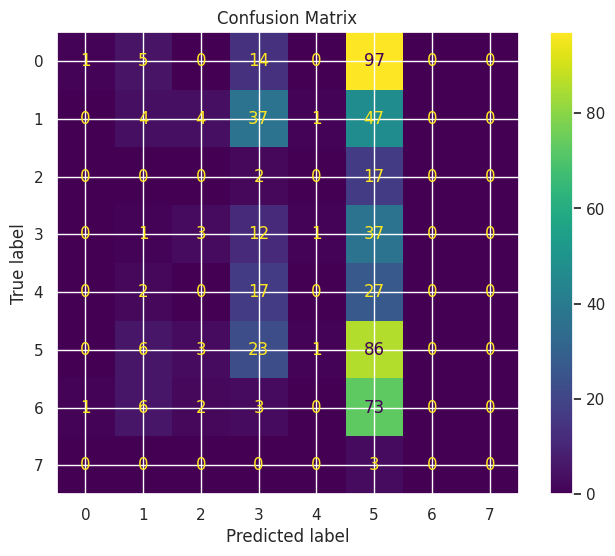

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.4388
Precision: 0.3147
Recall: 0.4388
F1: 0.3607
Kappa: 0.2988
Error Rate: 0.5612

TEST
Accuracy: 0.1772
Precision: 0.1199
Recall: 0.1772
F1: 0.1283
Kappa: 0.0172
Error Rate: 0.8228
Gap (overfitting): 0.2615

CV
Mean: 0.4454
Std: 0.0214
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



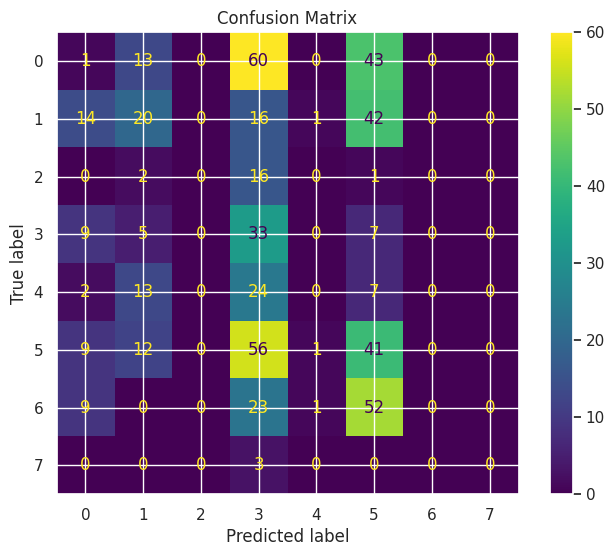

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.3411
Precision: 0.2350
Recall: 0.3411
F1: 0.2570
Kappa: 0.1822
Error Rate: 0.6589

TEST
Accuracy: 0.1698
Precision: 0.0935
Recall: 0.1698
F1: 0.0580
Kappa: -0.0048
Error Rate: 0.8302
Gap (overfitting): 0.1713

CV
Mean: 0.3563
Std: 0.0141
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



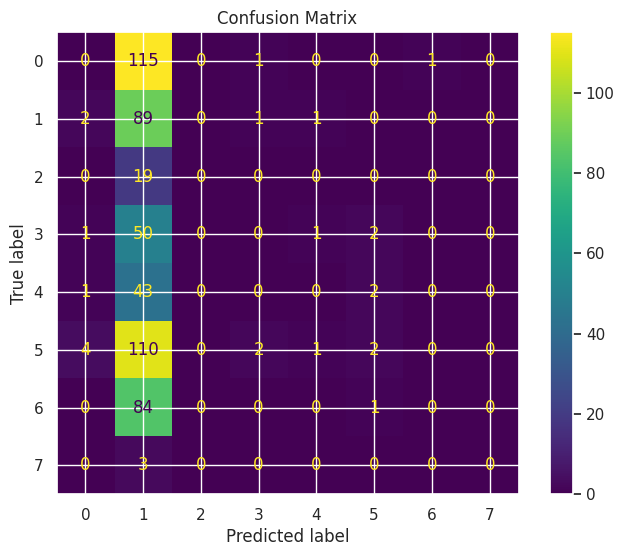

In [4]:
models_mlp_gru = {}

models_mlp_gru['MLP_GRU_rmsprop'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru['MLP_GRU_adam'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru['MLP_GRU_sgd_momentum'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_mlp_gru['MLP_GRU_adam_lowLR'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_mlp_gru, "mlp_gru_experiments")

/tmp/ipykernel_1145/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_1
------------------------------
TRAIN
Accuracy: 0.4588
Precision: 0.4103
Recall: 0.4588
F1: 0.4129
Kappa: 0.3230
Error Rate: 0.5412

TEST
Accuracy: 0.1194
Precision: 0.2356
Recall: 0.1194
F1: 0.0920
Kappa: 0.0075
Error Rate: 0.8806
Gap (overfitting): 0.3394

CV
Mean: 0.4773
Std: 0.0367
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



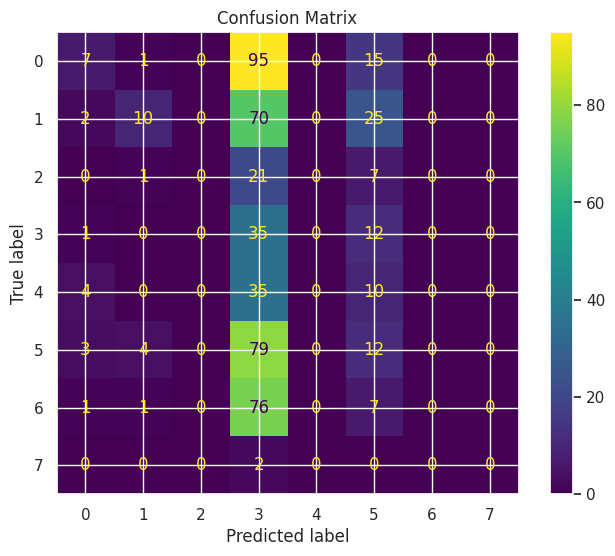

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_2
------------------------------
TRAIN
Accuracy: 0.5460
Precision: 0.5237
Recall: 0.5460
F1: 0.5170
Kappa: 0.4365
Error Rate: 0.4540

TEST
Accuracy: 0.1679
Precision: 0.2102
Recall: 0.1679
F1: 0.0664
Kappa: -0.0090
Error Rate: 0.8321
Gap (overfitting): 0.3781

CV
Mean: 0.5462
Std: 0.0190
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



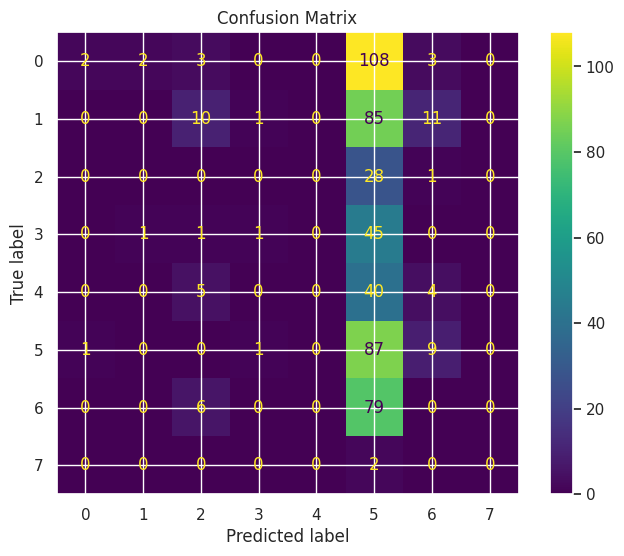

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_3
------------------------------
TRAIN
Accuracy: 0.2242
Precision: 0.0503
Recall: 0.2242
F1: 0.0821
Kappa: 0.0000
Error Rate: 0.7758

TEST
Accuracy: 0.2201
Precision: 0.0485
Recall: 0.2201
F1: 0.0794
Kappa: 0.0000
Error Rate: 0.7799
Gap (overfitting): 0.0040

CV
Mean: 0.2230
Std: 0.0161
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



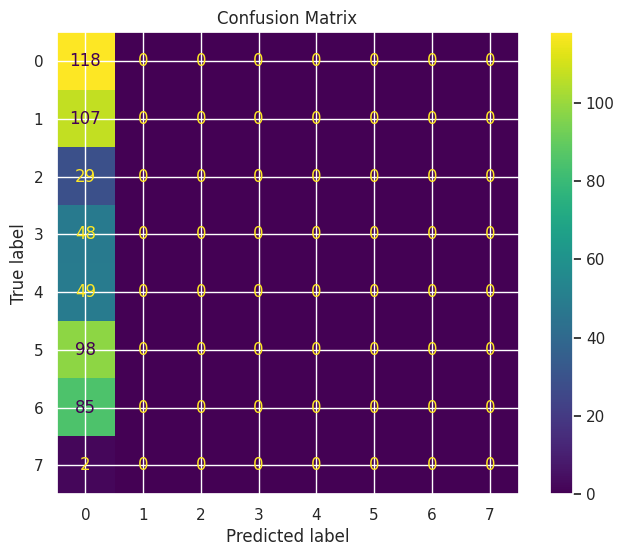

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_4
------------------------------
TRAIN
Accuracy: 0.5164
Precision: 0.4648
Recall: 0.5164
F1: 0.4758
Kappa: 0.3973
Error Rate: 0.4836

TEST
Accuracy: 0.1679
Precision: 0.0854
Recall: 0.1679
F1: 0.0791
Kappa: -0.0006
Error Rate: 0.8321
Gap (overfitting): 0.3485

CV
Mean: 0.5227
Std: 0.0168
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.3, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



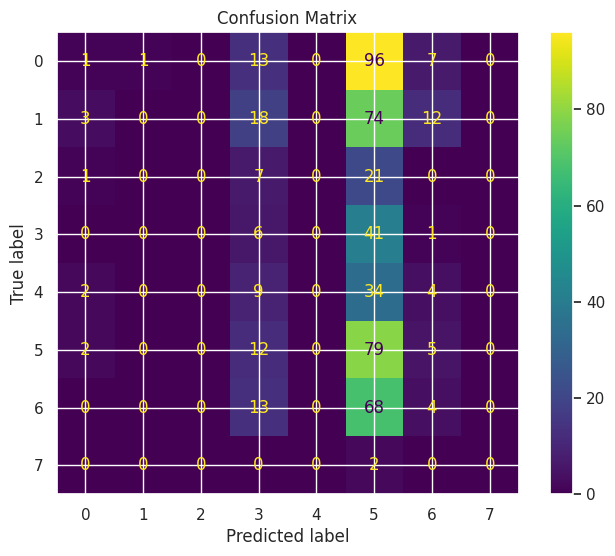

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_5
------------------------------
TRAIN
Accuracy: 0.6157
Precision: 0.6394
Recall: 0.6157
F1: 0.6025
Kappa: 0.5262
Error Rate: 0.3843

TEST
Accuracy: 0.1082
Precision: 0.2407
Recall: 0.1082
F1: 0.0690
Kappa: 0.0182
Error Rate: 0.8918
Gap (overfitting): 0.5075

CV
Mean: 0.7838
Std: 0.0379
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



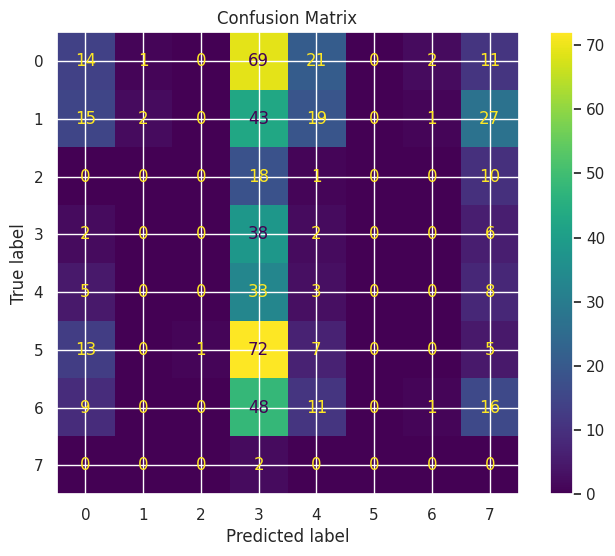

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_6
------------------------------
TRAIN
Accuracy: 0.9456
Precision: 0.9467
Recall: 0.9456
F1: 0.9449
Kappa: 0.9341
Error Rate: 0.0544

TEST
Accuracy: 0.1754
Precision: 0.0336
Recall: 0.1754
F1: 0.0563
Kappa: -0.0070
Error Rate: 0.8246
Gap (overfitting): 0.7702

CV
Mean: 0.9059
Std: 0.0427
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



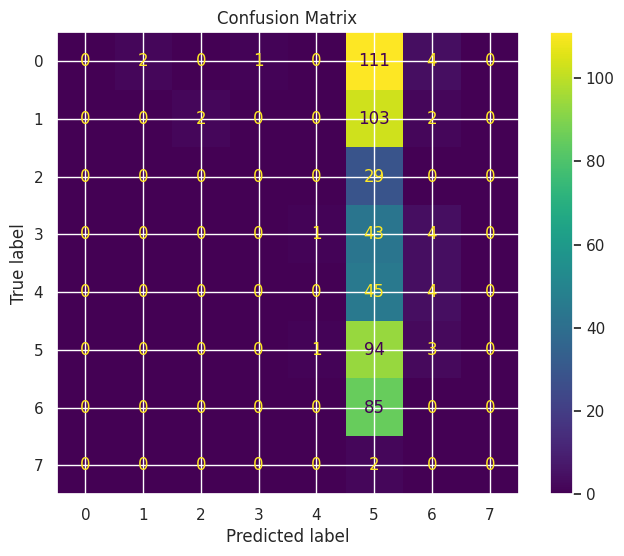

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_7
------------------------------
TRAIN
Accuracy: 0.8719
Precision: 0.8777
Recall: 0.8719
F1: 0.8694
Kappa: 0.8438
Error Rate: 0.1281

TEST
Accuracy: 0.0877
Precision: 0.1544
Recall: 0.0877
F1: 0.0213
Kappa: -0.0038
Error Rate: 0.9123
Gap (overfitting): 0.7842

CV
Mean: 0.8090
Std: 0.0518
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



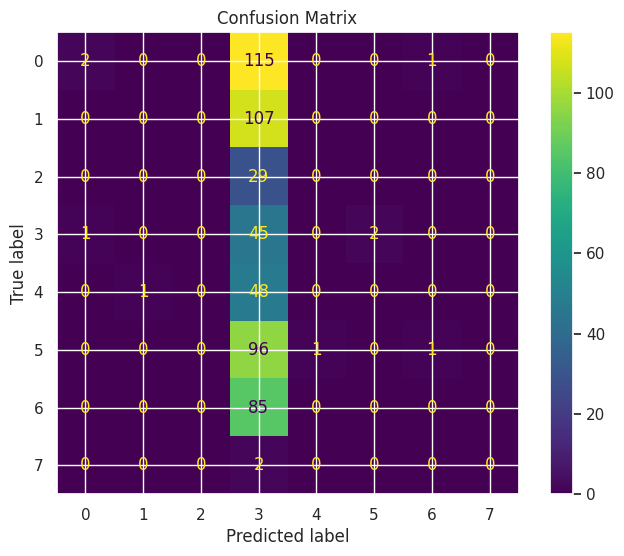

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_8
------------------------------
TRAIN
Accuracy: 0.4283
Precision: 0.4107
Recall: 0.4283
F1: 0.3795
Kappa: 0.2841
Error Rate: 0.5717

TEST
Accuracy: 0.2239
Precision: 0.2146
Recall: 0.2239
F1: 0.1638
Kappa: 0.0603
Error Rate: 0.7761
Gap (overfitting): 0.2045

CV
Mean: 0.4499
Std: 0.0118
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



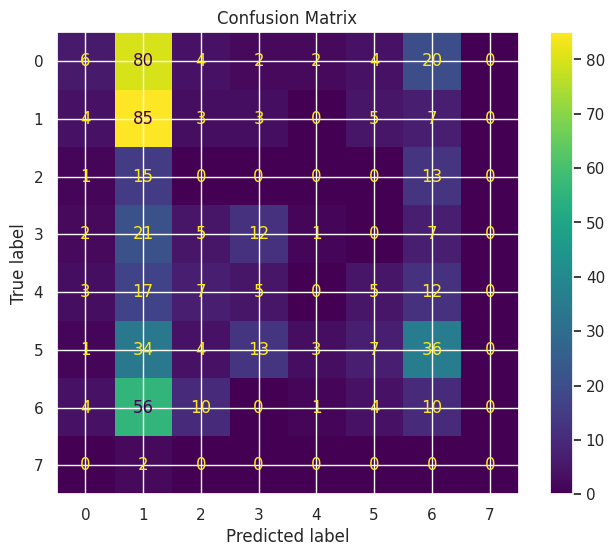

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_9
------------------------------
TRAIN
Accuracy: 0.5524
Precision: 0.5697
Recall: 0.5524
F1: 0.5351
Kappa: 0.4454
Error Rate: 0.4476

TEST
Accuracy: 0.1474
Precision: 0.1553
Recall: 0.1474
F1: 0.0726
Kappa: 0.0060
Error Rate: 0.8526
Gap (overfitting): 0.4051

CV
Mean: 0.5574
Std: 0.0155
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



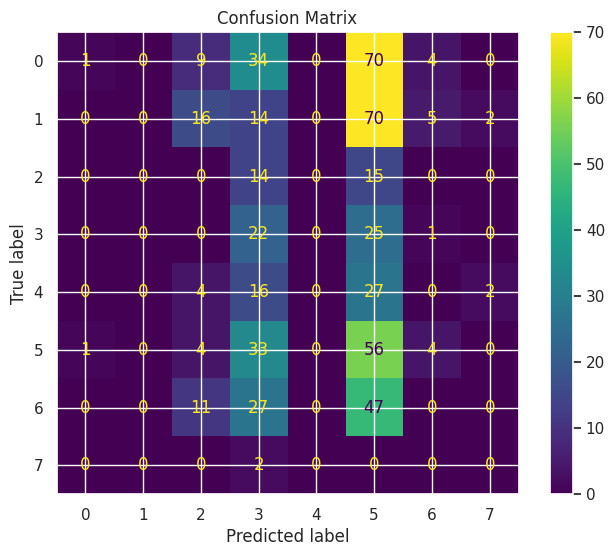

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_10
------------------------------
TRAIN
Accuracy: 0.4476
Precision: 0.4097
Recall: 0.4476
F1: 0.4118
Kappa: 0.3253
Error Rate: 0.5524

TEST
Accuracy: 0.0933
Precision: 0.1638
Recall: 0.0933
F1: 0.0255
Kappa: 0.0019
Error Rate: 0.9067
Gap (overfitting): 0.3543

CV
Mean: 0.4510
Std: 0.0209
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



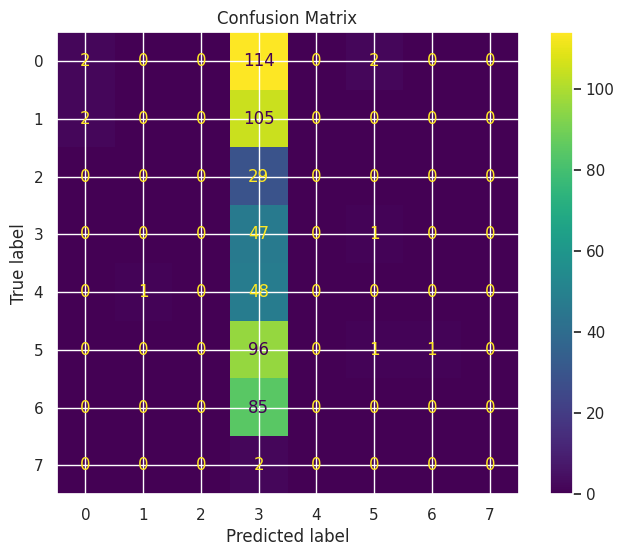

In [5]:
models_mlp_gru_f1 = {}

# ============================================================
# 1º MELHOR: MLP_GRU_sgd_momentum
# ============================================================


models_mlp_gru_f1['MLP_GRU_1'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f1['MLP_GRU_2'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16,), mlp_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# MLP 2 camadas + GRU 2 camadas
models_mlp_gru_f1['MLP_GRU_3'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização
models_mlp_gru_f1['MLP_GRU_4'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16,), mlp_dropout=0.3,
    gru_hidden=16, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# 2º MELHOR: MLP_GRU_rmsprop
# ============================================================

models_mlp_gru_f1['MLP_GRU_5'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

models_mlp_gru_f1['MLP_GRU_6'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16,), mlp_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f1['MLP_GRU_7'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# 3º MELHOR: MLP_GRU_adam_lowLR
# ============================================================


models_mlp_gru_f1['MLP_GRU_8'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f1['MLP_GRU_9'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16,), mlp_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f1['MLP_GRU_10'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_mlp_gru_f1, "mlp_gru_fase_1")

/tmp/ipykernel_1145/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_11
------------------------------
TRAIN
Accuracy: 0.3955
Precision: 0.3640
Recall: 0.3955
F1: 0.3346
Kappa: 0.2422
Error Rate: 0.6045

TEST
Accuracy: 0.2183
Precision: 0.1530
Recall: 0.2183
F1: 0.1283
Kappa: 0.0419
Error Rate: 0.7817
Gap (overfitting): 0.1772

CV
Mean: 0.4084
Std: 0.0094
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



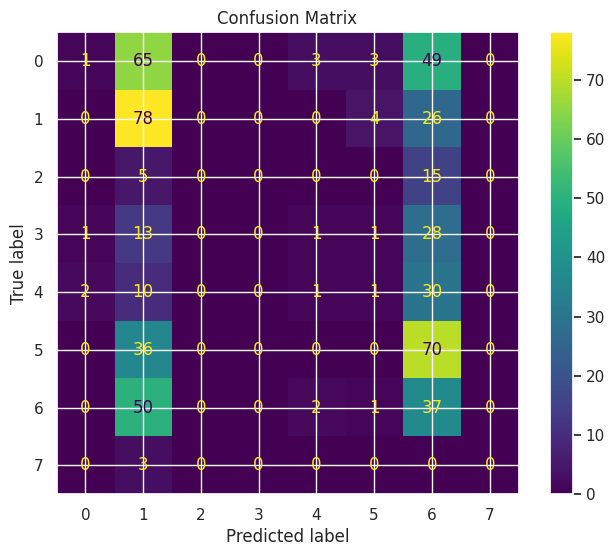

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_12
------------------------------
TRAIN
Accuracy: 0.4484
Precision: 0.4615
Recall: 0.4484
F1: 0.4038
Kappa: 0.3112
Error Rate: 0.5516

TEST
Accuracy: 0.1828
Precision: 0.2210
Recall: 0.1828
F1: 0.1683
Kappa: -0.0038
Error Rate: 0.8172
Gap (overfitting): 0.2655

CV
Mean: 0.4252
Std: 0.0181
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



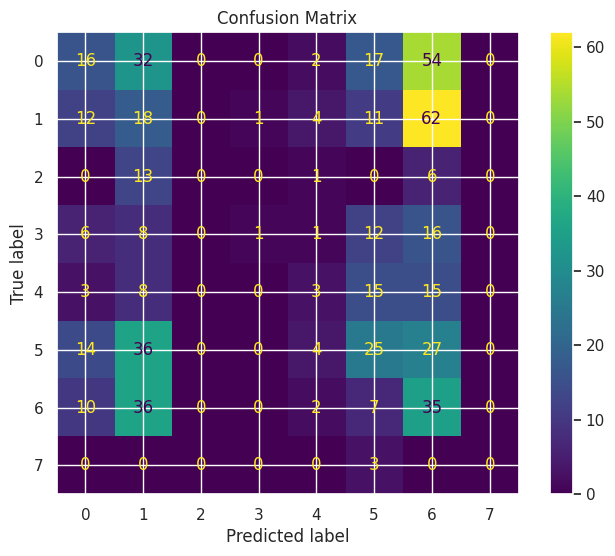


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_13
------------------------------
TRAIN
Accuracy: 0.6517
Precision: 0.6832
Recall: 0.6517
F1: 0.6498
Kappa: 0.5775
Error Rate: 0.3483

TEST
Accuracy: 0.1231
Precision: 0.2409
Recall: 0.1231
F1: 0.1014
Kappa: 0.0337
Error Rate: 0.8769
Gap (overfitting): 0.5286

CV
Mean: 0.6975
Std: 0.0481
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



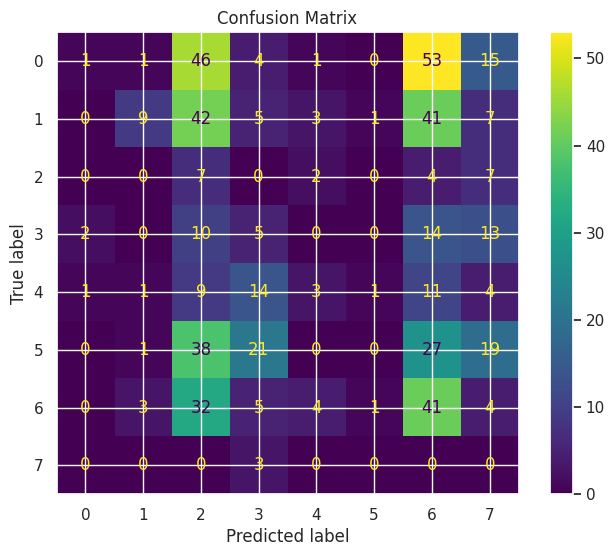

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_14
------------------------------
TRAIN
Accuracy: 0.3955
Precision: 0.3640
Recall: 0.3955
F1: 0.3346
Kappa: 0.2422
Error Rate: 0.6045

TEST
Accuracy: 0.2183
Precision: 0.1530
Recall: 0.2183
F1: 0.1283
Kappa: 0.0419
Error Rate: 0.7817
Gap (overfitting): 0.1772

CV
Mean: 0.4084
Std: 0.0094
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



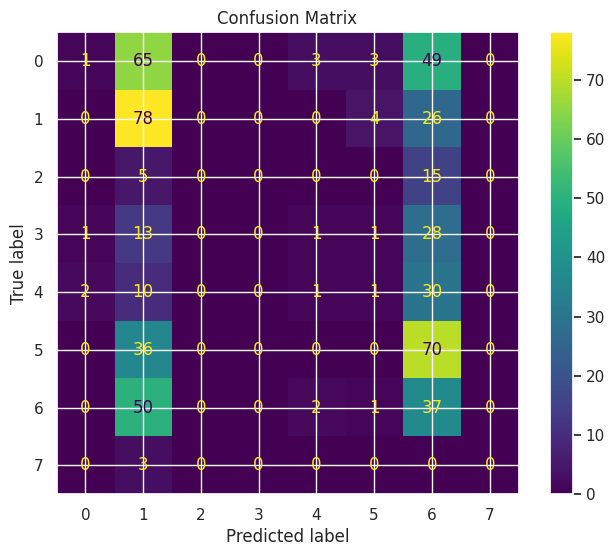

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_15
------------------------------
TRAIN
Accuracy: 0.4908
Precision: 0.5078
Recall: 0.4908
F1: 0.4620
Kappa: 0.3692
Error Rate: 0.5092

TEST
Accuracy: 0.1847
Precision: 0.2413
Recall: 0.1847
F1: 0.1449
Kappa: 0.0195
Error Rate: 0.8153
Gap (overfitting): 0.3061

CV
Mean: 0.4936
Std: 0.0167
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



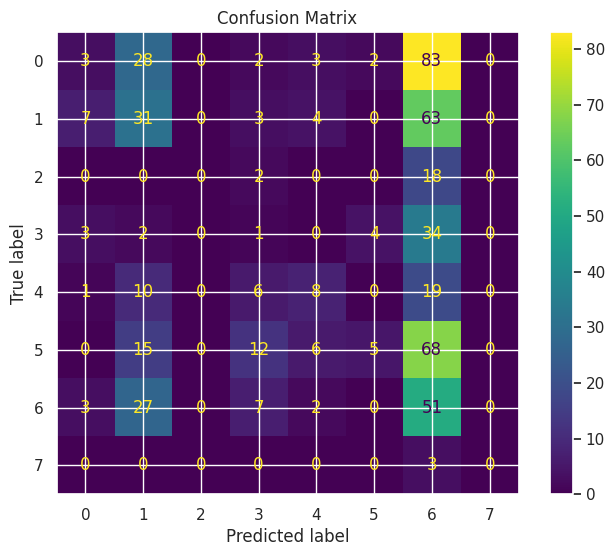

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_16
------------------------------
TRAIN
Accuracy: 0.4219
Precision: 0.4306
Recall: 0.4219
F1: 0.3575
Kappa: 0.2925
Error Rate: 0.5781

TEST
Accuracy: 0.1437
Precision: 0.2070
Recall: 0.1437
F1: 0.1111
Kappa: 0.0196
Error Rate: 0.8563
Gap (overfitting): 0.2783

CV
Mean: 0.4174
Std: 0.0188
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



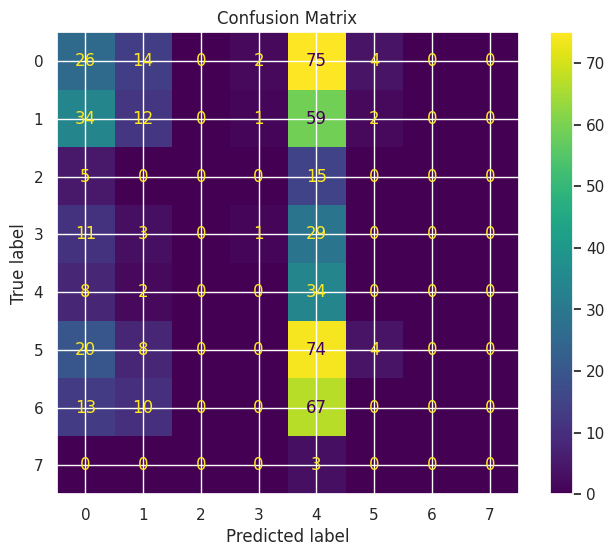

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_17
------------------------------
TRAIN
Accuracy: 0.3955
Precision: 0.3640
Recall: 0.3955
F1: 0.3346
Kappa: 0.2422
Error Rate: 0.6045

TEST
Accuracy: 0.2183
Precision: 0.1530
Recall: 0.2183
F1: 0.1283
Kappa: 0.0419
Error Rate: 0.7817
Gap (overfitting): 0.1772

CV
Mean: 0.4084
Std: 0.0094
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



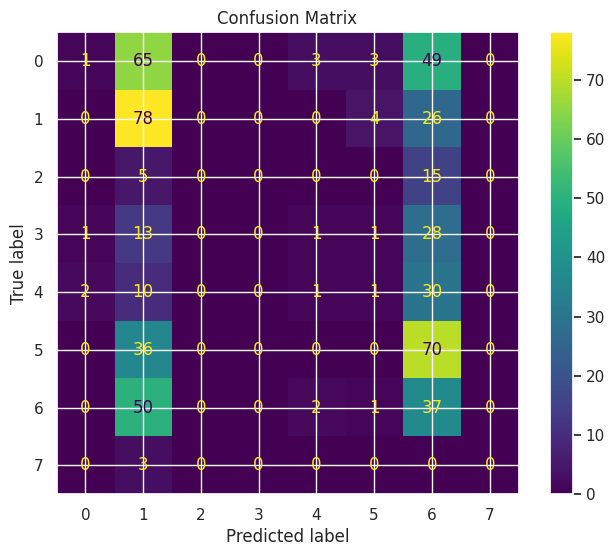

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_GRU_18
------------------------------
TRAIN
Accuracy: 0.3667
Precision: 0.3787
Recall: 0.3667
F1: 0.2898
Kappa: 0.2034
Error Rate: 0.6333

TEST
Accuracy: 0.2146
Precision: 0.1611
Recall: 0.2146
F1: 0.1219
Kappa: 0.0276
Error Rate: 0.7854
Gap (overfitting): 0.1521

CV
Mean: 0.3832
Std: 0.0163
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.1, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



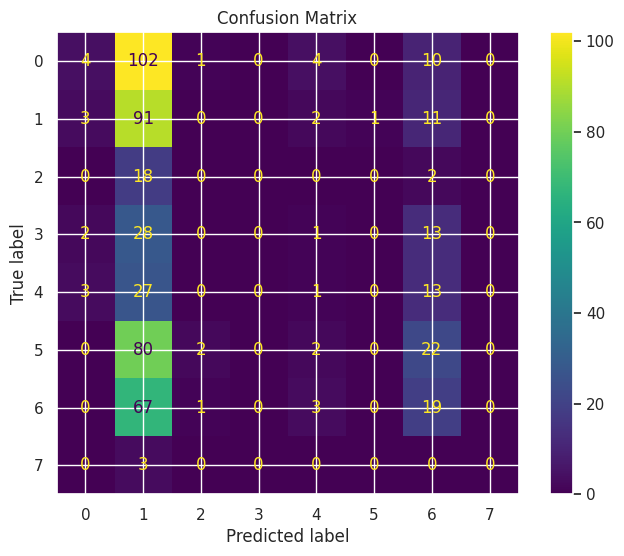

In [6]:
models_mlp_gru_f2 = {}

# ============================================================
# OTIMIZADORES
# ============================================================


models_mlp_gru_f2['MLP_GRU_11'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f2['MLP_GRU_12'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f2['MLP_GRU_13'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS
# ============================================================

# hidden = 30
models_mlp_gru_f2['MLP_GRU_14'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# hidden = 50
models_mlp_gru_f2['MLP_GRU_15'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16,), mlp_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 2 camadas MLP + 2 camadas GRU (50_8)
models_mlp_gru_f2['MLP_GRU_16'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_mlp_gru_f2['MLP_GRU_17'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f2['MLP_GRU_18'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.1,
    gru_hidden=8, gru_layers=1, gru_dropout=0.1, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)



main(models_mlp_gru_f2, "mlp_gru_fase_2")

/tmp/ipykernel_1145/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd
------------------------------
TRAIN
Accuracy: 0.4652
Precision: 0.4161
Recall: 0.4652
F1: 0.4256
Kappa: 0.3341
Error Rate: 0.5348

TEST
Accuracy: 0.2257
Precision: 0.2244
Recall: 0.2257
F1: 0.1611
Kappa: 0.0298
Error Rate: 0.7743
Gap (overfitting): 0.2394

CV
Mean: 0.4392
Std: 0.0491
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



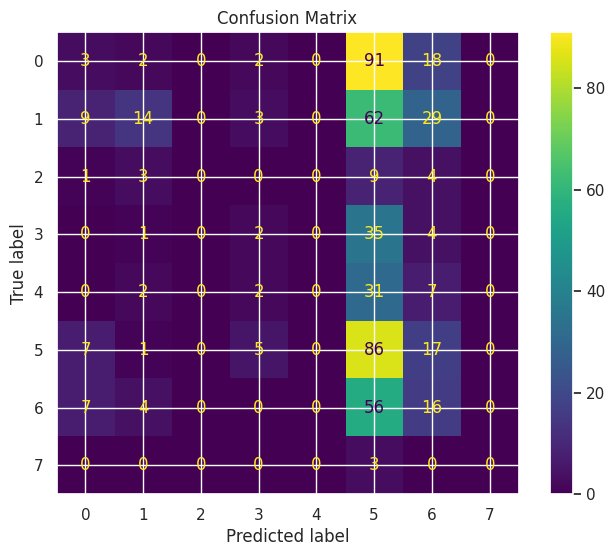

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_95
------------------------------
TRAIN
Accuracy: 0.5516
Precision: 0.5524
Recall: 0.5516
F1: 0.5161
Kappa: 0.4423
Error Rate: 0.4484

TEST
Accuracy: 0.2146
Precision: 0.2298
Recall: 0.2146
F1: 0.1352
Kappa: 0.0217
Error Rate: 0.7854
Gap (overfitting): 0.3371

CV
Mean: 0.5070
Std: 0.0577
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



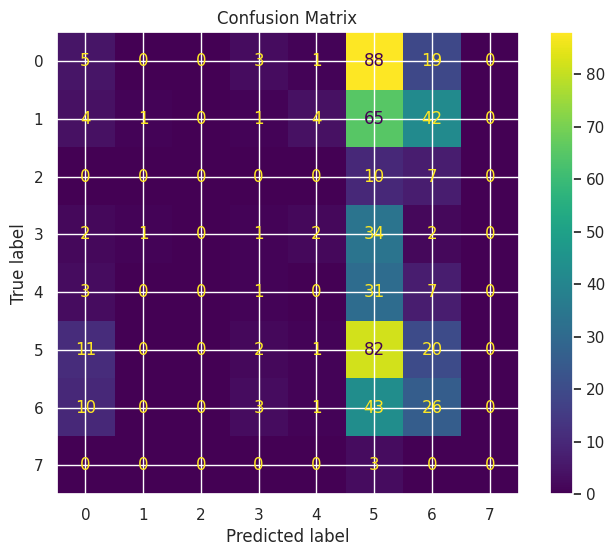

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd
------------------------------
TRAIN
Accuracy: 0.4580
Precision: 0.4125
Recall: 0.4580
F1: 0.4143
Kappa: 0.3242
Error Rate: 0.5420

TEST
Accuracy: 0.2313
Precision: 0.2191
Recall: 0.2313
F1: 0.1559
Kappa: 0.0955
Error Rate: 0.7687
Gap (overfitting): 0.2266

CV
Mean: 0.4426
Std: 0.0506
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



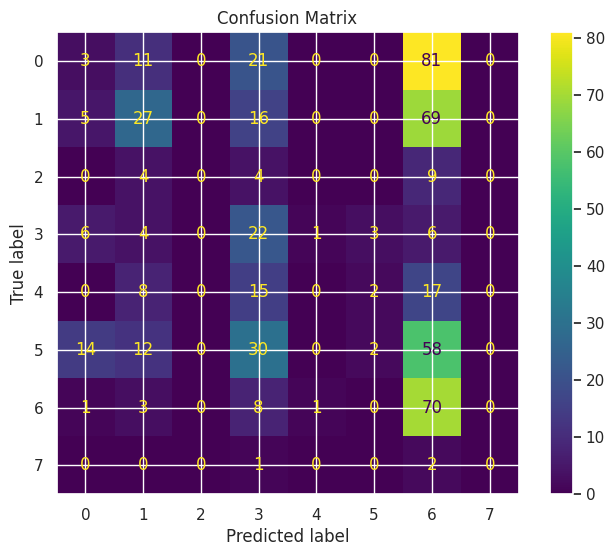

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd_95
------------------------------
TRAIN
Accuracy: 0.5701
Precision: 0.5944
Recall: 0.5701
F1: 0.5522
Kappa: 0.4658
Error Rate: 0.4299

TEST
Accuracy: 0.1903
Precision: 0.2265
Recall: 0.1903
F1: 0.1550
Kappa: 0.0454
Error Rate: 0.8097
Gap (overfitting): 0.3798

CV
Mean: 0.5563
Std: 0.0843
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



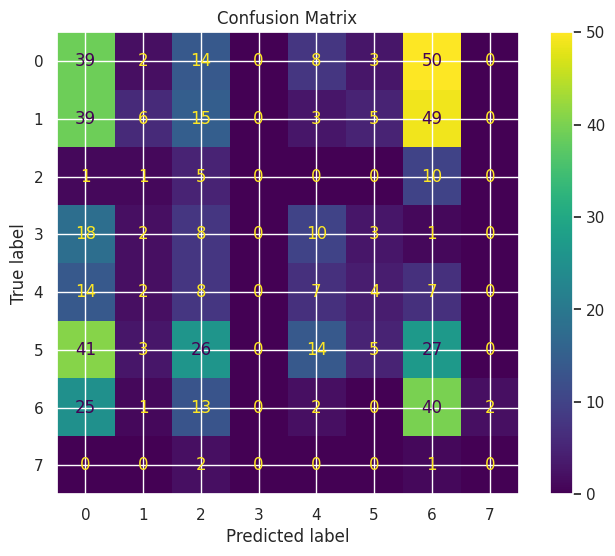

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_sgd
------------------------------
TRAIN
Accuracy: 0.2306
Precision: 0.0532
Recall: 0.2306
F1: 0.0864
Kappa: 0.0000
Error Rate: 0.7694

TEST
Accuracy: 0.2164
Precision: 0.0468
Recall: 0.2164
F1: 0.0770
Kappa: 0.0000
Error Rate: 0.7836
Gap (overfitting): 0.0142

CV
Mean: 0.2263
Std: 0.0179
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



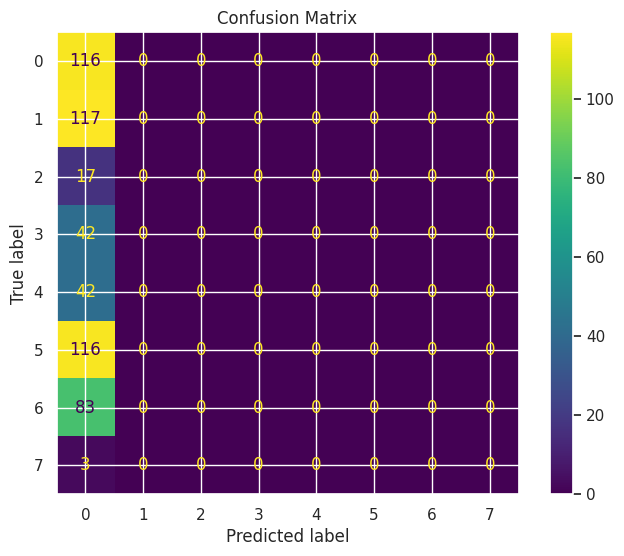

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_sgd_95
------------------------------
TRAIN
Accuracy: 0.2842
Precision: 0.1245
Recall: 0.2842
F1: 0.1702
Kappa: 0.0877
Error Rate: 0.7158

TEST
Accuracy: 0.2257
Precision: 0.1114
Recall: 0.2257
F1: 0.1046
Kappa: 0.0118
Error Rate: 0.7743
Gap (overfitting): 0.0585

CV
Mean: 0.3070
Std: 0.0241
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



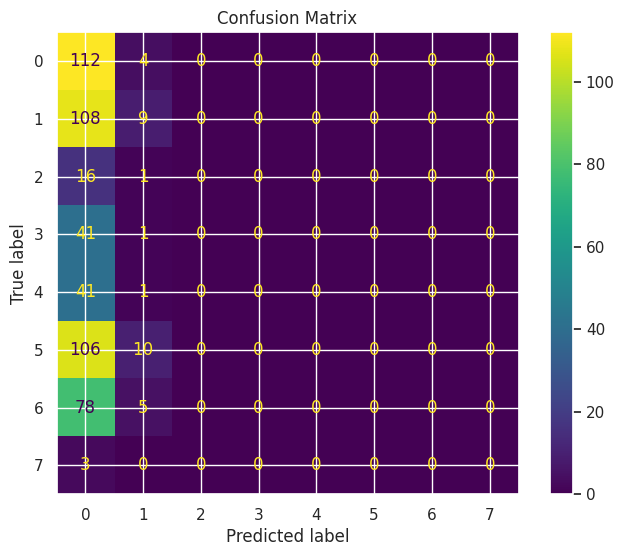

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_adam1e-4
------------------------------
TRAIN
Accuracy: 0.3355
Precision: 0.3335
Recall: 0.3355
F1: 0.2662
Kappa: 0.1571
Error Rate: 0.6645

TEST
Accuracy: 0.1847
Precision: 0.0895
Recall: 0.1847
F1: 0.0952
Kappa: -0.0319
Error Rate: 0.8153
Gap (overfitting): 0.1508

CV
Mean: 0.3272
Std: 0.0065
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.2, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



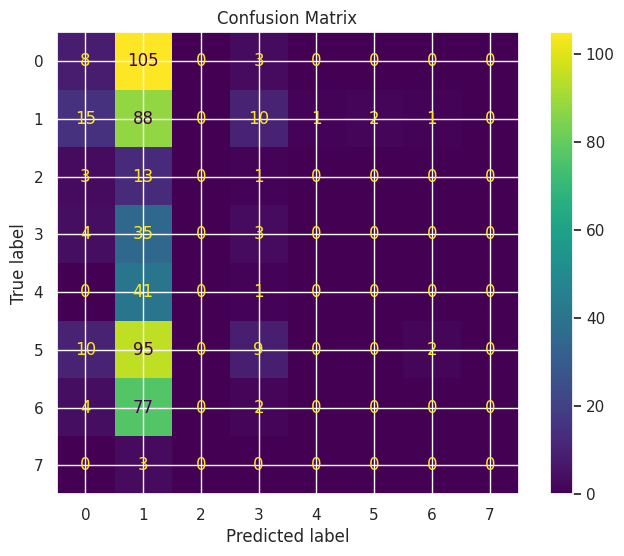

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_adam1e-4
------------------------------
TRAIN
Accuracy: 0.4548
Precision: 0.4162
Recall: 0.4548
F1: 0.4205
Kappa: 0.3183
Error Rate: 0.5452

TEST
Accuracy: 0.1810
Precision: 0.1991
Recall: 0.1810
F1: 0.1033
Kappa: 0.0219
Error Rate: 0.8190
Gap (overfitting): 0.2738

CV
Mean: 0.4812
Std: 0.0318
------------------------------
Model params:
{'mlp_hidden_layers': (16,), 'mlp_dropout': 0.2, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



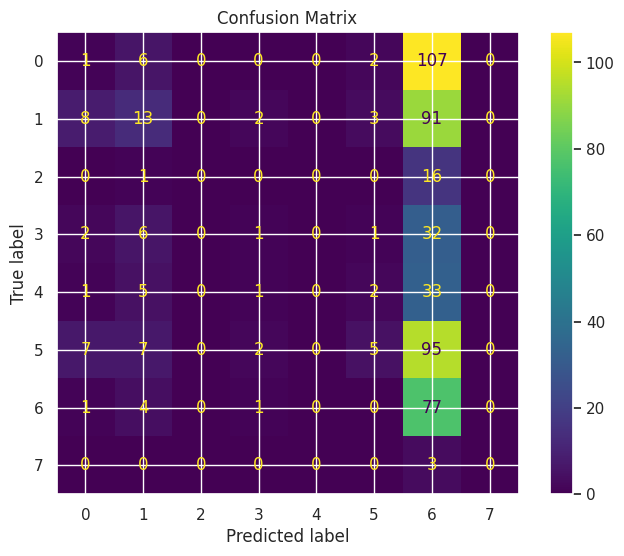

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_adam1e-4
------------------------------
TRAIN
Accuracy: 0.2722
Precision: 0.1612
Recall: 0.2722
F1: 0.1686
Kappa: 0.0907
Error Rate: 0.7278

TEST
Accuracy: 0.2183
Precision: 0.1219
Recall: 0.2183
F1: 0.1185
Kappa: 0.0399
Error Rate: 0.7817
Gap (overfitting): 0.0539

CV
Mean: 0.2835
Std: 0.0212
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.2, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.2, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



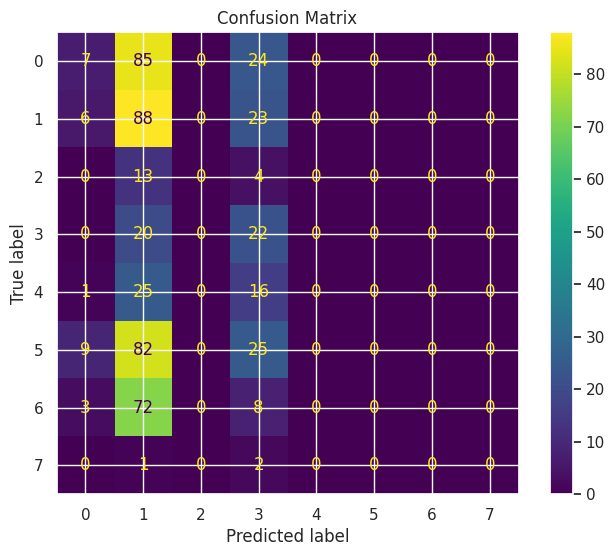

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_d2
------------------------------
TRAIN
Accuracy: 0.4540
Precision: 0.4206
Recall: 0.4540
F1: 0.4007
Kappa: 0.3142
Error Rate: 0.5460

TEST
Accuracy: 0.2146
Precision: 0.1591
Recall: 0.2146
F1: 0.1799
Kappa: 0.0306
Error Rate: 0.7854
Gap (overfitting): 0.2394

CV
Mean: 0.4420
Std: 0.0447
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.2, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



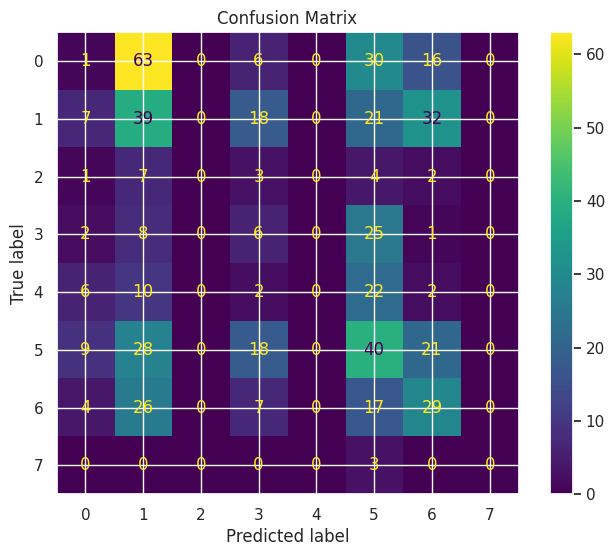

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd_d3
------------------------------
TRAIN
Accuracy: 0.4363
Precision: 0.4502
Recall: 0.4363
F1: 0.3655
Kappa: 0.2885
Error Rate: 0.5637

TEST
Accuracy: 0.2034
Precision: 0.1919
Recall: 0.2034
F1: 0.1722
Kappa: 0.0176
Error Rate: 0.7966
Gap (overfitting): 0.2330

CV
Mean: 0.4218
Std: 0.0330
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.3, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



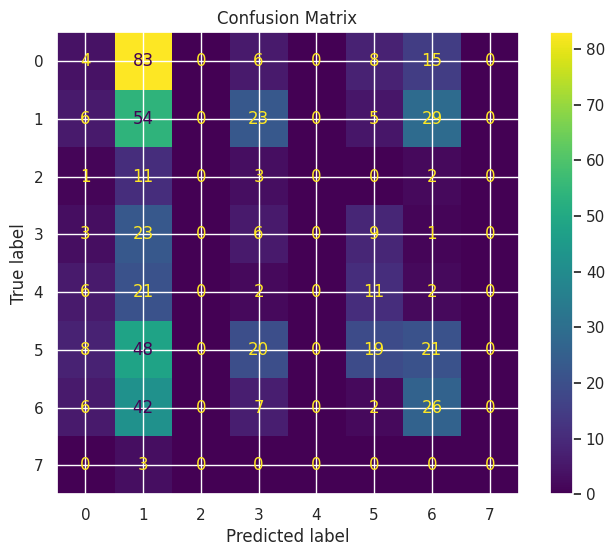

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30sgdlowLR
------------------------------
TRAIN
Accuracy: 0.2306
Precision: 0.0532
Recall: 0.2306
F1: 0.0864
Kappa: 0.0000
Error Rate: 0.7694

TEST
Accuracy: 0.1828
Precision: 0.1626
Recall: 0.1828
F1: 0.1066
Kappa: -0.0448
Error Rate: 0.8172
Gap (overfitting): 0.0477

CV
Mean: 0.2319
Std: 0.0256
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



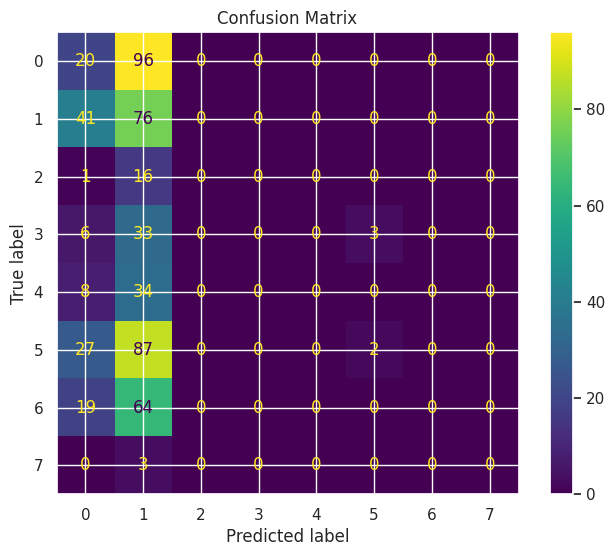

In [7]:
models_mlp_gru_f3 = {}

# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_mlp_gru_f3['F2_30_sgd'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f3['F2_30_sgd_95'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f3['F2_50_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16,), mlp_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f3['F2_50_sgd_95'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16,), mlp_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f3['F2_50_25_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)



models_mlp_gru_f3['F2_50_25_sgd_95'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_mlp_gru_f3['F2_30_adam1e-4'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.2,
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_mlp_gru_f3['F2_50_adam1e-4'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16,), mlp_dropout=0.2,
    gru_hidden=16, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

models_mlp_gru_f3['F2_50_25_adam1e-4'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16, 8), mlp_dropout=0.2,
    gru_hidden=8, gru_layers=2, gru_dropout=0.2, fc_hidden=(25,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_mlp_gru_f3['F2_30_sgd_d2'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.2,
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




models_mlp_gru_f3['F2_30_sgd_d3'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.3,
    gru_hidden=8, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




models_mlp_gru_f3['F2_30sgdlowLR'] = MLP_GRU_Hybrid(
    mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




main(models_mlp_gru_f3, "mlp_gru_fase_3")

/tmp/ipykernel_1145/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3d0_sgd
------------------------------
TRAIN
Accuracy: 0.4227
Precision: 0.3096
Recall: 0.4227
F1: 0.3496
Kappa: 0.2747
Error Rate: 0.5773

TEST
Accuracy: 0.1828
Precision: 0.2243
Recall: 0.1828
F1: 0.0755
Kappa: 0.0106
Error Rate: 0.8172
Gap (overfitting): 0.2399

CV
Mean: 0.4118
Std: 0.0223
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



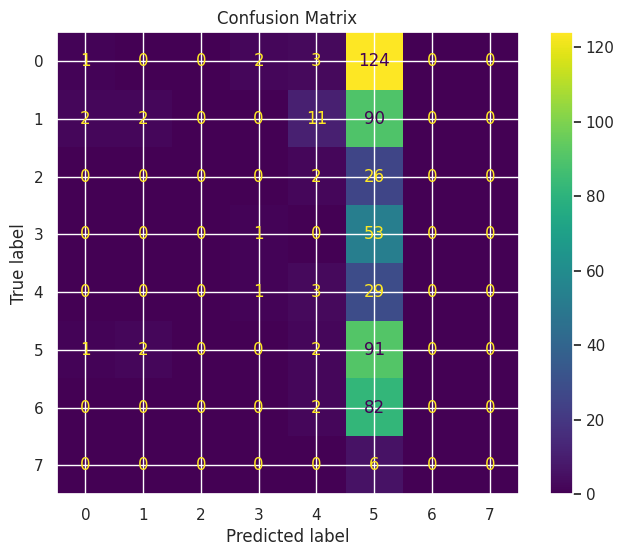

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr5e-4d0_sgd
------------------------------
TRAIN
Accuracy: 0.3587
Precision: 0.2279
Recall: 0.3587
F1: 0.2771
Kappa: 0.1860
Error Rate: 0.6413

TEST
Accuracy: 0.1660
Precision: 0.2103
Recall: 0.1660
F1: 0.1285
Kappa: 0.0034
Error Rate: 0.8340
Gap (overfitting): 0.1926

CV
Mean: 0.3669
Std: 0.0157
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



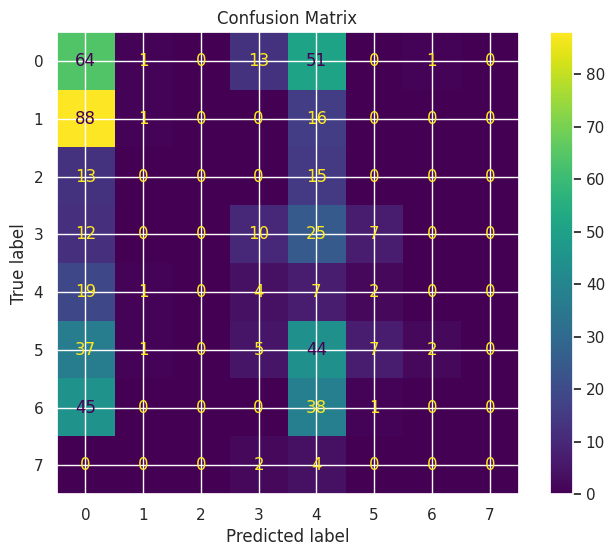

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr1e-3d3_sgd
------------------------------
TRAIN
Accuracy: 0.4107
Precision: 0.3175
Recall: 0.4107
F1: 0.3301
Kappa: 0.2593
Error Rate: 0.5893

TEST
Accuracy: 0.1455
Precision: 0.2745
Recall: 0.1455
F1: 0.0934
Kappa: 0.0275
Error Rate: 0.8545
Gap (overfitting): 0.2652

CV
Mean: 0.4011
Std: 0.0242
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.3, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



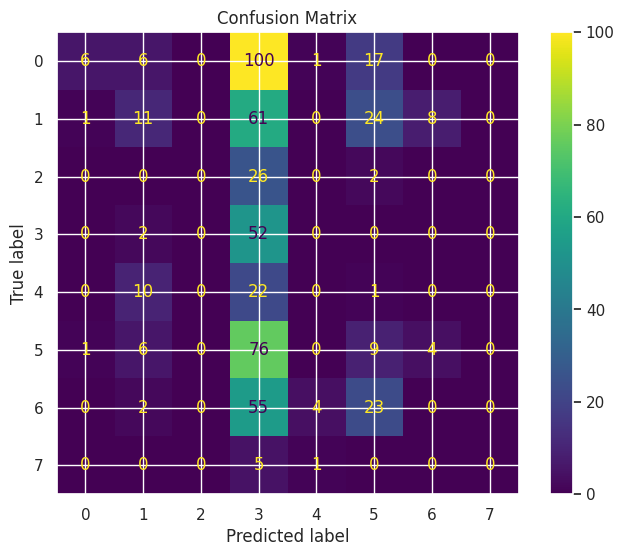

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_lr5e-4d2_sgd
------------------------------
TRAIN
Accuracy: 0.3539
Precision: 0.2239
Recall: 0.3539
F1: 0.2712
Kappa: 0.1809
Error Rate: 0.6461

TEST
Accuracy: 0.2369
Precision: 0.2090
Recall: 0.2369
F1: 0.1416
Kappa: 0.0397
Error Rate: 0.7631
Gap (overfitting): 0.1169

CV
Mean: 0.3557
Std: 0.0210
------------------------------
Model params:
{'mlp_hidden_layers': (8,), 'mlp_dropout': 0.2, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



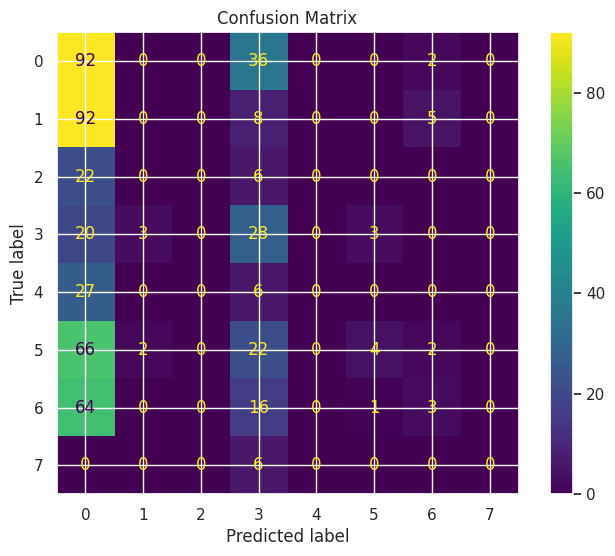

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_lr1e-3d0_sgd
------------------------------
TRAIN
Accuracy: 0.2290
Precision: 0.0524
Recall: 0.2290
F1: 0.0853
Kappa: 0.0000
Error Rate: 0.7710

TEST
Accuracy: 0.2425
Precision: 0.0588
Recall: 0.2425
F1: 0.0947
Kappa: 0.0000
Error Rate: 0.7575
Gap (overfitting): -0.0136

CV
Mean: 0.2331
Std: 0.0148
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



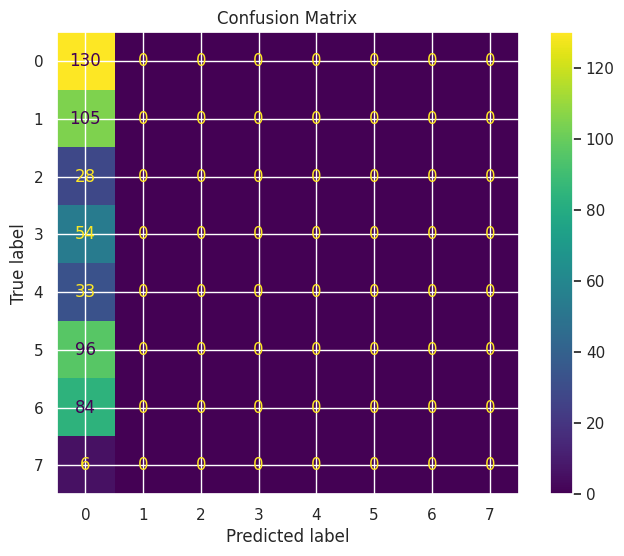

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_lr5e-4d0_sgd
------------------------------
TRAIN
Accuracy: 0.2290
Precision: 0.0524
Recall: 0.2290
F1: 0.0853
Kappa: 0.0000
Error Rate: 0.7710

TEST
Accuracy: 0.2425
Precision: 0.0588
Recall: 0.2425
F1: 0.0947
Kappa: 0.0000
Error Rate: 0.7575
Gap (overfitting): -0.0136

CV
Mean: 0.2331
Std: 0.0148
------------------------------
Model params:
{'mlp_hidden_layers': (16, 8), 'mlp_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (25,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0005, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



OSError: [Errno 36] File name too long: "Classification/mlp_gru_fase_4/images/confusion_matrix_6xN+4xS-1_05+0_95+1_1+0_9_MLP_GRU_Hybrid(epochs=500, fc_hidden=(25,), gru_dropout=0.0, gru_hidden=8,\n               gru_layers=2, input_size=21, learning_rate=0.0005,\n               mlp_dropout=0.0, mlp_hidden_layers=(16, 8), solver='sgd').png"

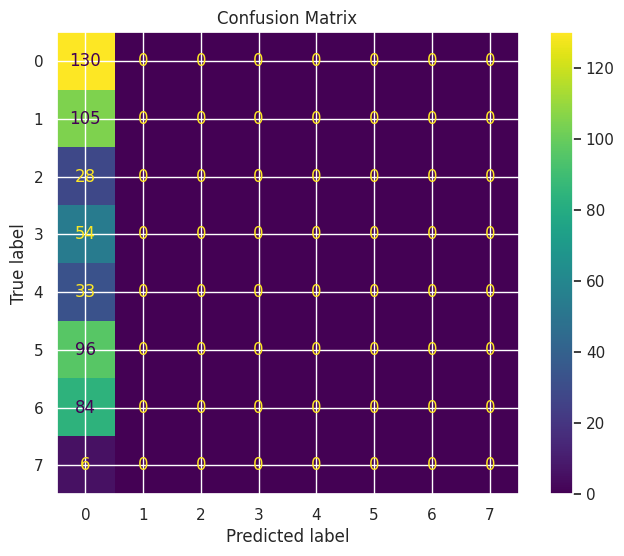

In [8]:
models_mlp_gru_f4 = {}


# ============================================================
# 🔥 SGD com arquitetura base (30)
# ============================================================




models_mlp_gru_f4['F3_30_lr1e-3d0_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




models_mlp_gru_f4['F3_30_lr5e-4d0_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(8,), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_mlp_gru_f4['F3_30_lr1e-3d3_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(8,), mlp_dropout=0.3,
    gru_hidden=8, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




models_mlp_gru_f4['F3_30_lr5e-4d2_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(8,), mlp_dropout=0.2,
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




# ============================================================
# 🔥 SGD com arquitetura 50_25 (2 camadas)
# ============================================================




models_mlp_gru_f4['F3_50_25_lr1e-3d0_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)




models_mlp_gru_f4['F3_50_25_lr5e-4d0_sgd'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16, 8), mlp_dropout=0.0,
    gru_hidden=8, gru_layers=2, gru_dropout=0.0, fc_hidden=(25,),
    solver='sgd', learning_rate=0.0005, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (Adam)
# ============================================================




models_mlp_gru_f4['F3_30_lr1e-d2_adam'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(8,), mlp_dropout=0.2,
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)




models_mlp_gru_f4['F3_50_25_lr1e-4_d2_adam'] = MLP_GRU_Hybrid(
   mlp_hidden_layers=(16, 8), mlp_dropout=0.2,
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)




main(models_mlp_gru_f4, "mlp_gru_fase_4")

In [3]:
class RNN_GRU_Hybrid(BaseEstimator, ClassifierMixin):
    """RNN + GRU empilhadas (duas camadas recorrentes diferentes)"""

    def __init__(self,
                 rnn_hidden=16,
                 rnn_layers=1,
                 rnn_dropout=0.2,
                 gru_hidden=16,
                 gru_layers=1,
                 gru_dropout=0.2,
                 fc_hidden=(8,),
                 input_size=None,
                 output_size=8,
                 solver='adam',           # ← ADICIONADO
                 learning_rate=0.001,
                 momentum=0.9,            # ← ADICIONADO
                 epochs=100,
                 batch_size=32,
                 random_state=42,
                 device='cpu'):

        self.rnn_hidden = rnn_hidden
        self.rnn_layers = rnn_layers
        self.rnn_dropout = rnn_dropout
        self.gru_hidden = gru_hidden
        self.gru_layers = gru_layers
        self.gru_dropout = gru_dropout
        self.fc_hidden = fc_hidden
        self.input_size = input_size
        self.output_size = output_size
        self.solver = solver              # ← NOVO
        self.learning_rate = learning_rate
        self.momentum = momentum          # ← NOVO
        self.epochs = epochs
        self.batch_size = batch_size
        self.random_state = random_state
        self.device = device if torch.cuda.is_available() else 'cpu'

        self.model = None
        self.optimizer = None
        self.criterion = None
        self.label_encoder = LabelEncoder()
        self.scaler = MinMaxScaler()

    def _build_model(self):
        class RNN_GRU_Model(nn.Module):
            def __init__(self, input_size, rnn_hidden, rnn_layers, rnn_dropout,
                         gru_hidden, gru_layers, gru_dropout, fc_hidden, output_size):
                super(RNN_GRU_Model, self).__init__()

                # Primeira camada: RNN
                self.rnn = nn.RNN(
                    input_size=input_size,
                    hidden_size=rnn_hidden,
                    num_layers=rnn_layers,
                    batch_first=True,
                    dropout=rnn_dropout if rnn_layers > 1 else 0,
                    nonlinearity='tanh'
                )

                self.rnn_dropout = nn.Dropout(rnn_dropout)

                # Segunda camada: GRU
                self.gru = nn.GRU(
                    input_size=rnn_hidden,
                    hidden_size=gru_hidden,
                    num_layers=gru_layers,
                    batch_first=True,
                    dropout=gru_dropout if gru_layers > 1 else 0
                )

                self.gru_dropout = nn.Dropout(gru_dropout)

                # Fully connected
                fc_layers = []
                prev_size = gru_hidden

                for hidden in fc_hidden:
                    fc_layers.append(nn.Linear(prev_size, hidden))
                    fc_layers.append(nn.ReLU())
                    fc_layers.append(nn.Dropout(rnn_dropout))
                    prev_size = hidden

                fc_layers.append(nn.Linear(prev_size, output_size))
                self.fc = nn.Sequential(*fc_layers)

            def forward(self, x):
                x = x.unsqueeze(1)  # (batch, seq_len=1, features)

                # RNN
                rnn_out, hidden_rnn = self.rnn(x)
                last_hidden_rnn = hidden_rnn[-1]  # (batch, rnn_hidden)
                x = self.rnn_dropout(last_hidden_rnn)

                # Reshape para GRU
                x = x.unsqueeze(1)  # (batch, 1, rnn_hidden)

                # GRU
                gru_out, hidden_gru = self.gru(x)
                last_hidden_gru = hidden_gru[-1]  # (batch, gru_hidden)

                x = self.gru_dropout(last_hidden_gru)
                x = self.fc(x)
                return x

        return RNN_GRU_Model(
            input_size=self.input_size,
            rnn_hidden=self.rnn_hidden,
            rnn_layers=self.rnn_layers,
            rnn_dropout=self.rnn_dropout,
            gru_hidden=self.gru_hidden,
            gru_layers=self.gru_layers,
            gru_dropout=self.gru_dropout,
            fc_hidden=self.fc_hidden,
            output_size=self.output_size
        )

    def fit(self, X, y):
        if isinstance(X, pd.DataFrame):
            X = X.values
        if isinstance(y, (pd.Series, pd.DataFrame)):
            y = y.values

        if self.input_size is None:
            self.input_size = X.shape[1]

        X_scaled = self.scaler.fit_transform(X)
        y_encoded = self.label_encoder.fit_transform(y)
        self.output_size = len(self.label_encoder.classes_)

        torch.manual_seed(self.random_state)
        self.model = self._build_model().to(self.device)

        # ============================================================
        # ADAPTADO: Escolher otimizador baseado em self.solver
        # ============================================================
        if self.solver == 'adam':
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)
        elif self.solver == 'sgd':
            self.optimizer = optim.SGD(self.model.parameters(), lr=self.learning_rate, momentum=self.momentum)
        elif self.solver == 'rmsprop':
            self.optimizer = optim.RMSprop(self.model.parameters(), lr=self.learning_rate)
        else:
            self.optimizer = optim.Adam(self.model.parameters(), lr=self.learning_rate)

        self.criterion = nn.CrossEntropyLoss()

        X_tensor = torch.FloatTensor(X_scaled).to(self.device)
        y_tensor = torch.LongTensor(y_encoded).to(self.device)

        dataset = TensorDataset(X_tensor, y_tensor)
        dataloader = DataLoader(dataset, batch_size=self.batch_size, shuffle=True)

        self.model.train()
        for epoch in range(self.epochs):
            total_loss = 0
            for batch_X, batch_y in dataloader:
                self.optimizer.zero_grad()
                outputs = self.model(batch_X)
                loss = self.criterion(outputs, batch_y)
                loss.backward()
                self.optimizer.step()
                total_loss += loss.item()

            #if (epoch + 1) % 20 == 0:
               # print(f"Epoch {epoch+1}/{self.epochs}, Loss: {total_loss/len(dataloader):.4f}")

        return self

    def predict(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = self.model(X_tensor)
            _, predicted = torch.max(outputs, 1)

        return self.label_encoder.inverse_transform(predicted.cpu().numpy())

    def predict_proba(self, X):
        if isinstance(X, pd.DataFrame):
            X = X.values

        self.model.eval()
        X_scaled = self.scaler.transform(X)
        X_tensor = torch.FloatTensor(X_scaled).to(self.device)

        with torch.no_grad():
            outputs = torch.softmax(self.model(X_tensor), dim=1)

        return outputs.cpu().numpy()

    def get_params(self, deep=True):
        return {
            'rnn_hidden': self.rnn_hidden,
            'rnn_layers': self.rnn_layers,
            'rnn_dropout': self.rnn_dropout,
            'gru_hidden': self.gru_hidden,
            'gru_layers': self.gru_layers,
            'gru_dropout': self.gru_dropout,
            'fc_hidden': self.fc_hidden,
            'input_size': self.input_size,
            'output_size': self.output_size,
            'solver': self.solver,           # ← NOVO
            'learning_rate': self.learning_rate,
            'momentum': self.momentum,       # ← NOVO
            'epochs': self.epochs,
            'batch_size': self.batch_size,
            'random_state': self.random_state,
            'device': self.device
        }

    def set_params(self, **params):
        for key, value in params.items():
            setattr(self, key, value)
        return self

/tmp/ipykernel_4941/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_rmsprop
------------------------------
TRAIN
Accuracy: 0.7398
Precision: 0.7685
Recall: 0.7398
F1: 0.7406
Kappa: 0.6810
Error Rate: 0.2602

TEST
Accuracy: 0.0970
Precision: 0.2355
Recall: 0.0970
F1: 0.1090
Kappa: 0.0405
Error Rate: 0.9030
Gap (overfitting): 0.6428

CV
Mean: 0.7535
Std: 0.0660
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



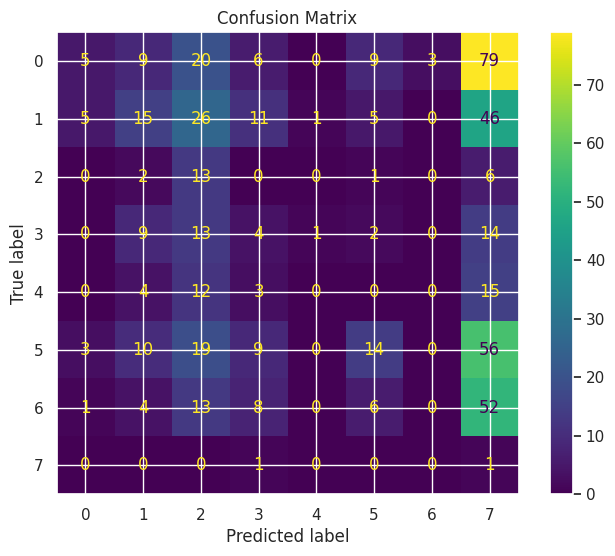

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_adam
------------------------------
TRAIN
Accuracy: 0.7782
Precision: 0.7891
Recall: 0.7782
F1: 0.7772
Kappa: 0.7297
Error Rate: 0.2218

TEST
Accuracy: 0.0746
Precision: 0.2016
Recall: 0.0746
F1: 0.0962
Kappa: 0.0171
Error Rate: 0.9254
Gap (overfitting): 0.7036

CV
Mean: 0.7849
Std: 0.0683
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



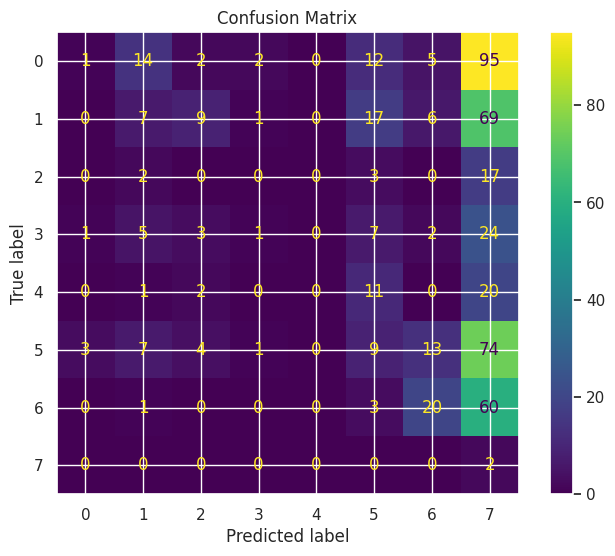

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.4908
Precision: 0.4287
Recall: 0.4908
F1: 0.4459
Kappa: 0.3673
Error Rate: 0.5092

TEST
Accuracy: 0.2407
Precision: 0.1867
Recall: 0.2407
F1: 0.1814
Kappa: 0.0567
Error Rate: 0.7593
Gap (overfitting): 0.2501

CV
Mean: 0.4885
Std: 0.0157
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



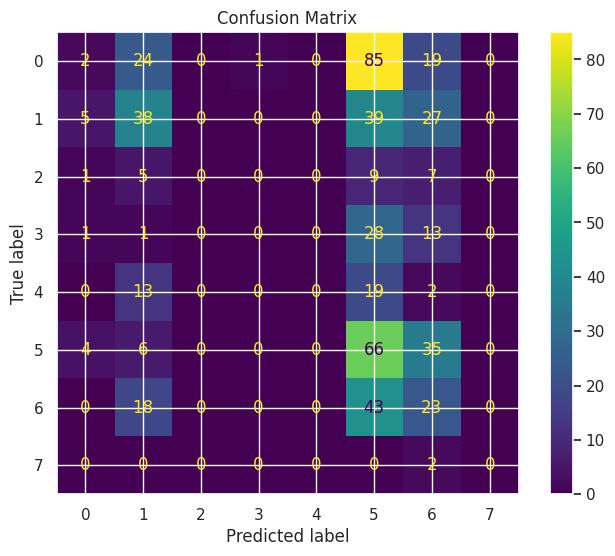

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.4468
Precision: 0.3963
Recall: 0.4468
F1: 0.4022
Kappa: 0.3116
Error Rate: 0.5532

TEST
Accuracy: 0.0448
Precision: 0.1660
Recall: 0.0448
F1: 0.0520
Kappa: -0.0116
Error Rate: 0.9552
Gap (overfitting): 0.4020

CV
Mean: 0.4835
Std: 0.0228
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



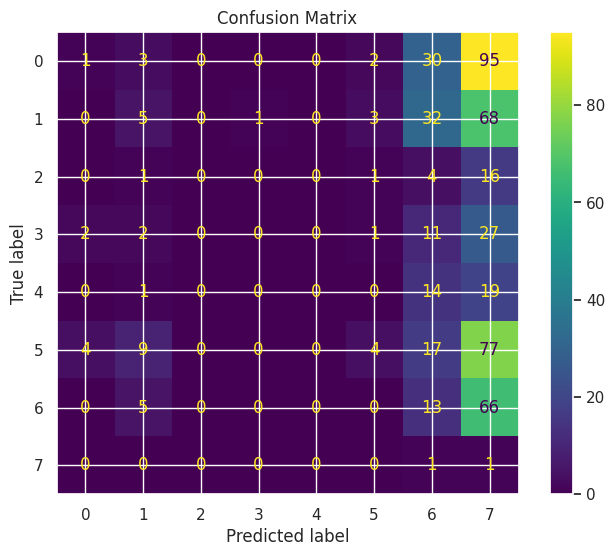

In [4]:
models_rnn_gru = {}


models_rnn_gru['RNN_GRU_rmsprop'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru['RNN_GRU_adam'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru['RNN_GRU_sgd_momentum'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru['RNN_GRU_adam_lowLR'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_gru, "rnn_gru_experiments")

/tmp/ipykernel_4941/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_30
------------------------------
TRAIN
Accuracy: 0.4628
Precision: 0.4017
Recall: 0.4628
F1: 0.4208
Kappa: 0.3361
Error Rate: 0.5372

TEST
Accuracy: 0.2463
Precision: 0.1628
Recall: 0.2463
F1: 0.1798
Kappa: 0.0817
Error Rate: 0.7537
Gap (overfitting): 0.2165

CV
Mean: 0.4555
Std: 0.0427
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



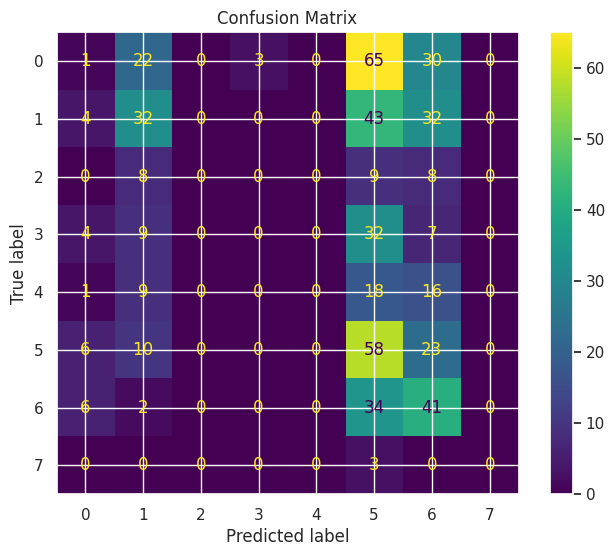

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_50
------------------------------
TRAIN
Accuracy: 0.4908
Precision: 0.4877
Recall: 0.4908
F1: 0.4594
Kappa: 0.3671
Error Rate: 0.5092

TEST
Accuracy: 0.2164
Precision: 0.1764
Recall: 0.2164
F1: 0.1636
Kappa: 0.0542
Error Rate: 0.7836
Gap (overfitting): 0.2744

CV
Mean: 0.4868
Std: 0.0452
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



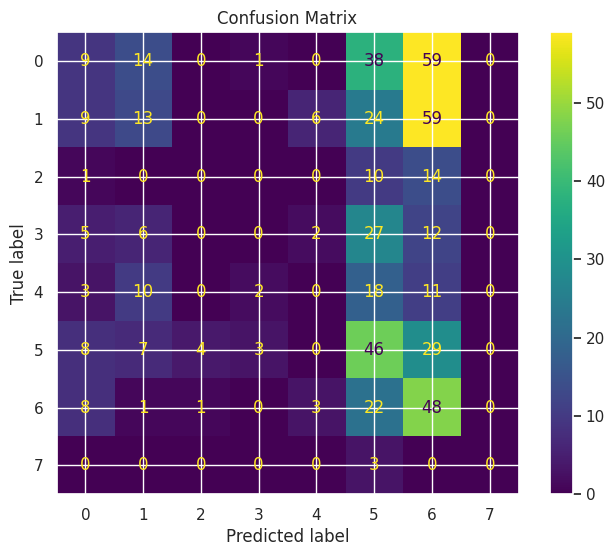

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_50_16
------------------------------
TRAIN
Accuracy: 0.2290
Precision: 0.1689
Recall: 0.2290
F1: 0.1016
Kappa: 0.0114
Error Rate: 0.7710

TEST
Accuracy: 0.2388
Precision: 0.0961
Recall: 0.2388
F1: 0.1368
Kappa: 0.0392
Error Rate: 0.7612
Gap (overfitting): -0.0098

CV
Mean: 0.2246
Std: 0.0091
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



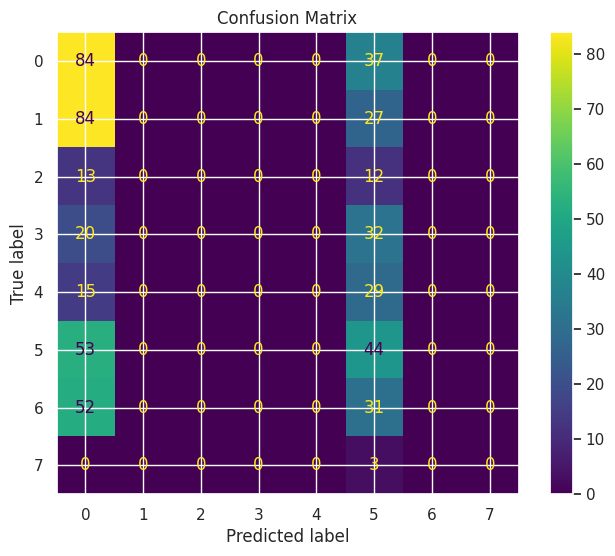

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_eg1e3
------------------------------
TRAIN
Accuracy: 0.4668
Precision: 0.4320
Recall: 0.4668
F1: 0.4233
Kappa: 0.3369
Error Rate: 0.5332

TEST
Accuracy: 0.1940
Precision: 0.1891
Recall: 0.1940
F1: 0.1495
Kappa: 0.0483
Error Rate: 0.8060
Gap (overfitting): 0.2727

CV
Mean: 0.4487
Std: 0.0432
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.3, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



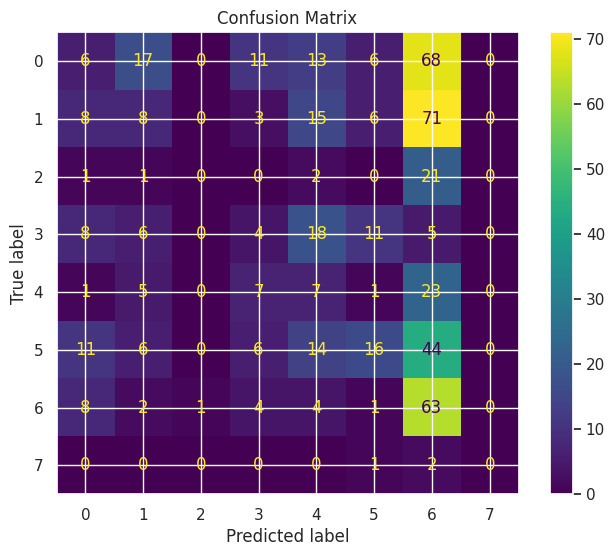

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_eg5e3
------------------------------
TRAIN
Accuracy: 0.4275
Precision: 0.3775
Recall: 0.4275
F1: 0.3780
Kappa: 0.2855
Error Rate: 0.5725

TEST
Accuracy: 0.1884
Precision: 0.1881
Recall: 0.1884
F1: 0.1454
Kappa: 0.0526
Error Rate: 0.8116
Gap (overfitting): 0.2391

CV
Mean: 0.4118
Std: 0.0352
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.5, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.5, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



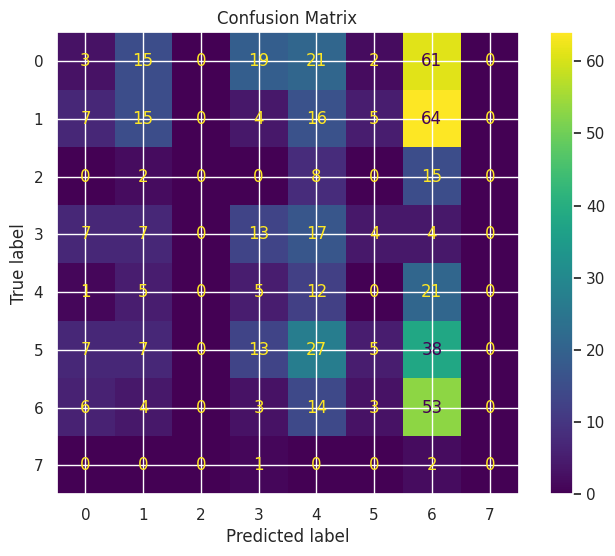


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_prop_30
------------------------------
TRAIN
Accuracy: 0.7054
Precision: 0.7527
Recall: 0.7054
F1: 0.7088
Kappa: 0.6397
Error Rate: 0.2946

TEST
Accuracy: 0.0466
Precision: 0.1647
Recall: 0.0466
F1: 0.0550
Kappa: 0.0016
Error Rate: 0.9534
Gap (overfitting): 0.6587

CV
Mean: 0.6801
Std: 0.0661
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



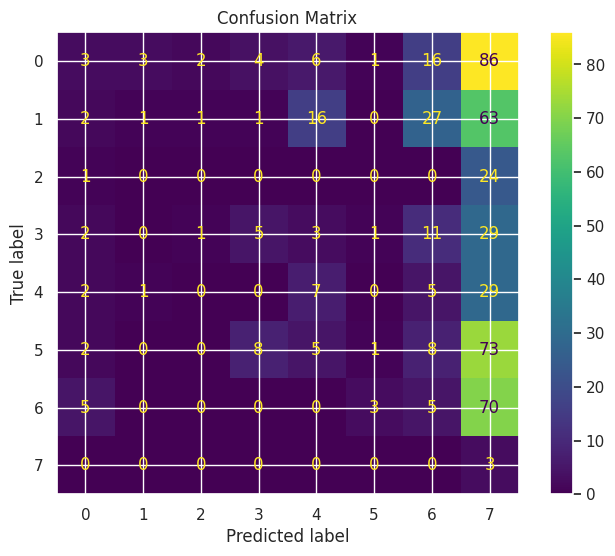

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_prop_50
------------------------------
TRAIN
Accuracy: 0.8647
Precision: 0.8718
Recall: 0.8647
F1: 0.8653
Kappa: 0.8355
Error Rate: 0.1353

TEST
Accuracy: 0.1810
Precision: 0.1696
Recall: 0.1810
F1: 0.1224
Kappa: 0.0181
Error Rate: 0.8190
Gap (overfitting): 0.6837

CV
Mean: 0.7916
Std: 0.0684
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



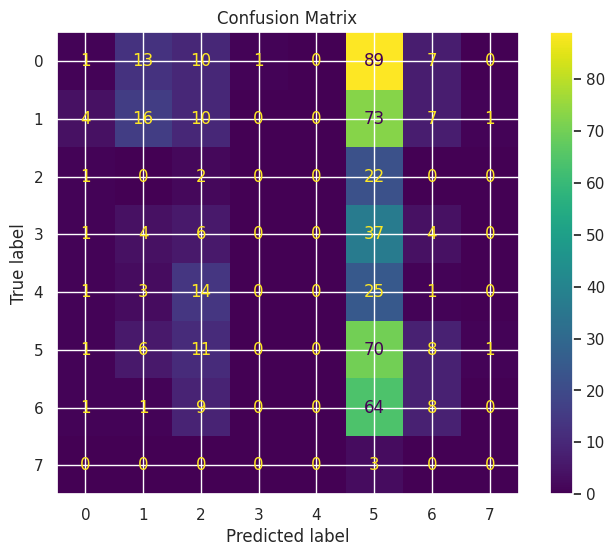


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_prop_50_16
------------------------------
TRAIN
Accuracy: 0.8359
Precision: 0.8583
Recall: 0.8359
F1: 0.8375
Kappa: 0.7998
Error Rate: 0.1641

TEST
Accuracy: 0.1325
Precision: 0.3059
Recall: 0.1325
F1: 0.1249
Kappa: 0.0160
Error Rate: 0.8675
Gap (overfitting): 0.7034

CV
Mean: 0.7681
Std: 0.1037
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



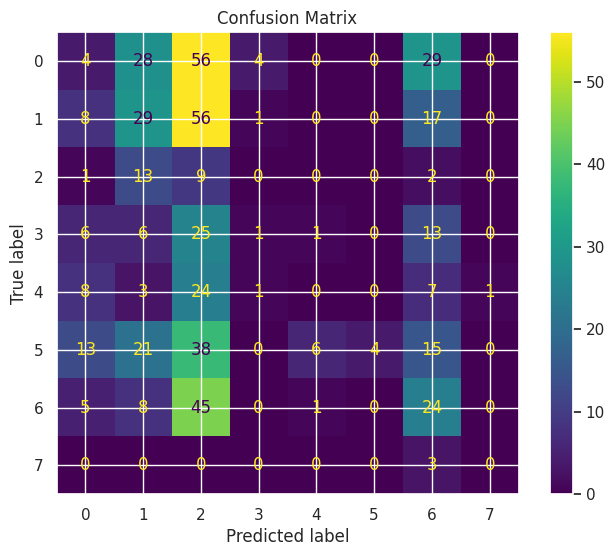

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_lowLR_30
------------------------------
TRAIN
Accuracy: 0.3851
Precision: 0.3346
Recall: 0.3851
F1: 0.3509
Kappa: 0.2386
Error Rate: 0.6149

TEST
Accuracy: 0.0392
Precision: 0.1271
Recall: 0.0392
F1: 0.0460
Kappa: -0.0078
Error Rate: 0.9608
Gap (overfitting): 0.3459

CV
Mean: 0.4056
Std: 0.0355
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



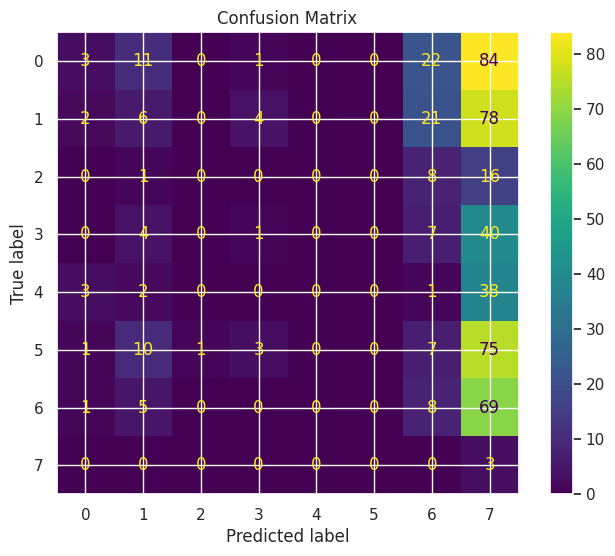

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_lowLR_50
------------------------------
TRAIN
Accuracy: 0.4620
Precision: 0.4658
Recall: 0.4620
F1: 0.4371
Kappa: 0.3344
Error Rate: 0.5380

TEST
Accuracy: 0.1940
Precision: 0.1365
Recall: 0.1940
F1: 0.1326
Kappa: 0.0528
Error Rate: 0.8060
Gap (overfitting): 0.2679

CV
Mean: 0.4964
Std: 0.0553
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



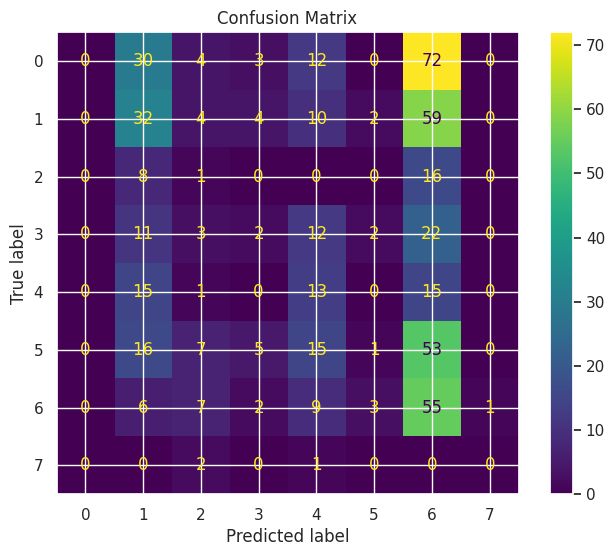

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_lowLR_50_16
------------------------------
TRAIN
Accuracy: 0.3963
Precision: 0.2921
Recall: 0.3963
F1: 0.3355
Kappa: 0.2450
Error Rate: 0.6037

TEST
Accuracy: 0.1847
Precision: 0.3354
Recall: 0.1847
F1: 0.1377
Kappa: 0.0599
Error Rate: 0.8153
Gap (overfitting): 0.2116

CV
Mean: 0.4246
Std: 0.0271
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



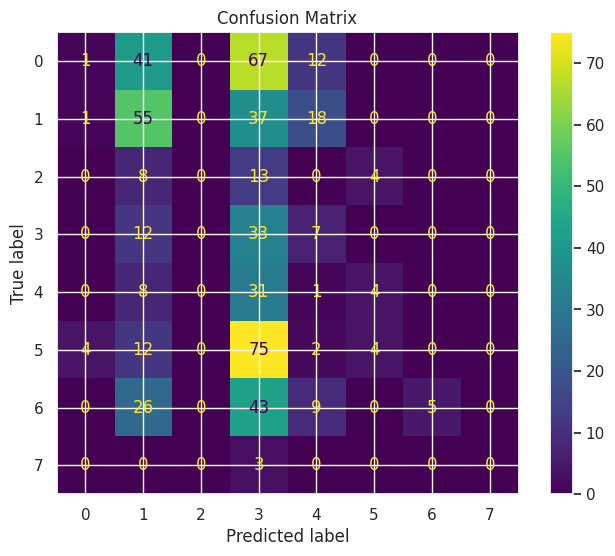

In [5]:
models_rnn_gru_f1 = {}


# ============================================================
# 1º MELHOR: RNN_GRU_sgd_momentum
# ============================================================


models_rnn_gru_f1['RNN_GRU_30'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f1['RNN_GRU_50'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# 2 camadas RNN + 2 camadas GRU
models_rnn_gru_f1['RNN_GRU_50_16'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# Regularização
models_rnn_gru_f1['RNN_GRU_eg1e3'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.3,
    gru_hidden=16, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f1['RNN_GRU_eg5e3'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.5,
    gru_hidden=16, gru_layers=1, gru_dropout=0.5, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 2º MELHOR: RNN_GRU_rmsprop
# ============================================================


models_rnn_gru_f1['RNN_GRU_prop_30'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f1['RNN_GRU_prop_50'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f1['RNN_GRU_prop_50_16'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 3º MELHOR: RNN_GRU_adam_lowLR
# ============================================================


models_rnn_gru_f1['RNN_GRU_lowLR_30'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f1['RNN_GRU_lowLR_50'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f1['RNN_GRU_lowLR_50_16'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_gru_f1, "rnn_gru_fase_1")



/tmp/ipykernel_4941/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_adam
------------------------------
TRAIN
Accuracy: 0.3835
Precision: 0.3914
Recall: 0.3835
F1: 0.3536
Kappa: 0.2338
Error Rate: 0.6165

TEST
Accuracy: 0.0728
Precision: 0.2289
Recall: 0.0728
F1: 0.0816
Kappa: 0.0258
Error Rate: 0.9272
Gap (overfitting): 0.3107

CV
Mean: 0.3681
Std: 0.0128
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



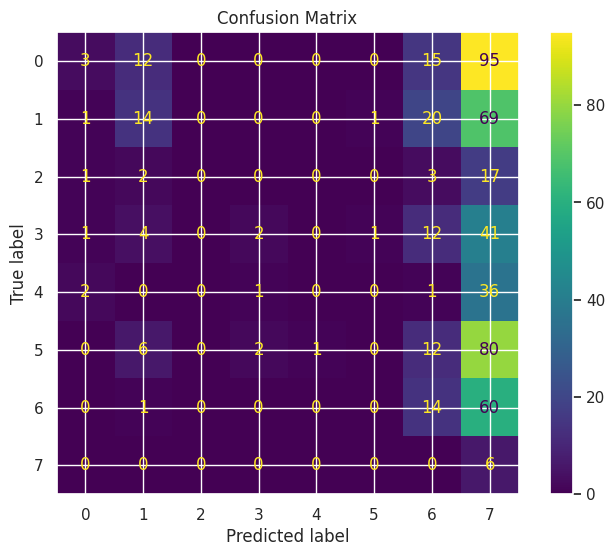

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_sgd
------------------------------
TRAIN
Accuracy: 0.4147
Precision: 0.3606
Recall: 0.4147
F1: 0.3784
Kappa: 0.2771
Error Rate: 0.5853

TEST
Accuracy: 0.1847
Precision: 0.2679
Recall: 0.1847
F1: 0.1347
Kappa: 0.0303
Error Rate: 0.8153
Gap (overfitting): 0.2300

CV
Mean: 0.4196
Std: 0.0239
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



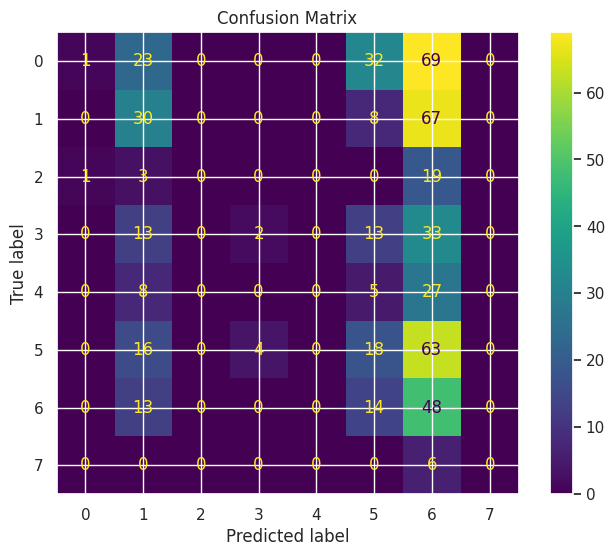


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_rmsprop
------------------------------
TRAIN
Accuracy: 0.7366
Precision: 0.7520
Recall: 0.7366
F1: 0.7325
Kappa: 0.6780
Error Rate: 0.2634

TEST
Accuracy: 0.0522
Precision: 0.1199
Recall: 0.0522
F1: 0.0447
Kappa: 0.0145
Error Rate: 0.9478
Gap (overfitting): 0.6844

CV
Mean: 0.6824
Std: 0.1026
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'rmsprop', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



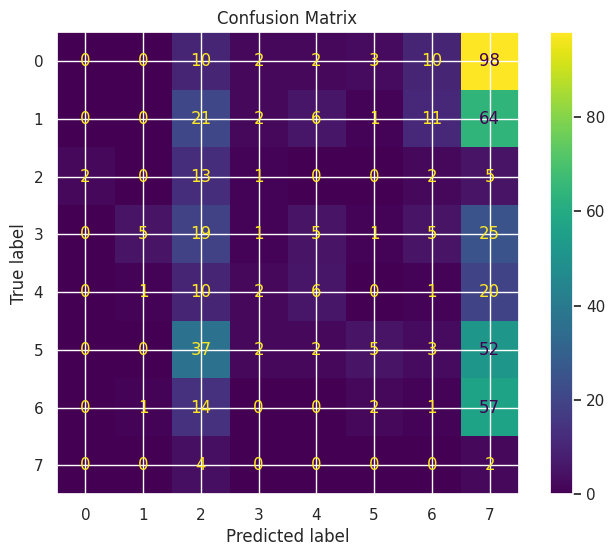

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_30
------------------------------
TRAIN
Accuracy: 0.3835
Precision: 0.3914
Recall: 0.3835
F1: 0.3536
Kappa: 0.2338
Error Rate: 0.6165

TEST
Accuracy: 0.0728
Precision: 0.2289
Recall: 0.0728
F1: 0.0816
Kappa: 0.0258
Error Rate: 0.9272
Gap (overfitting): 0.3107

CV
Mean: 0.3681
Std: 0.0128
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



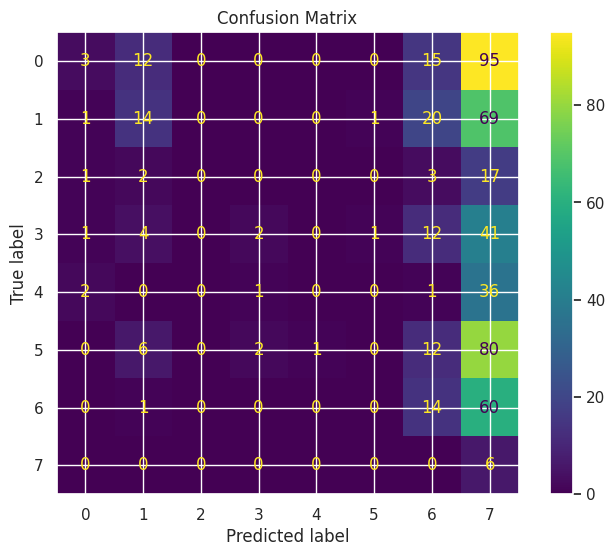

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GR_50
------------------------------
TRAIN
Accuracy: 0.4291
Precision: 0.4230
Recall: 0.4291
F1: 0.4023
Kappa: 0.2924
Error Rate: 0.5709

TEST
Accuracy: 0.1157
Precision: 0.1640
Recall: 0.1157
F1: 0.0939
Kappa: 0.0270
Error Rate: 0.8843
Gap (overfitting): 0.3135

CV
Mean: 0.4471
Std: 0.0174
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



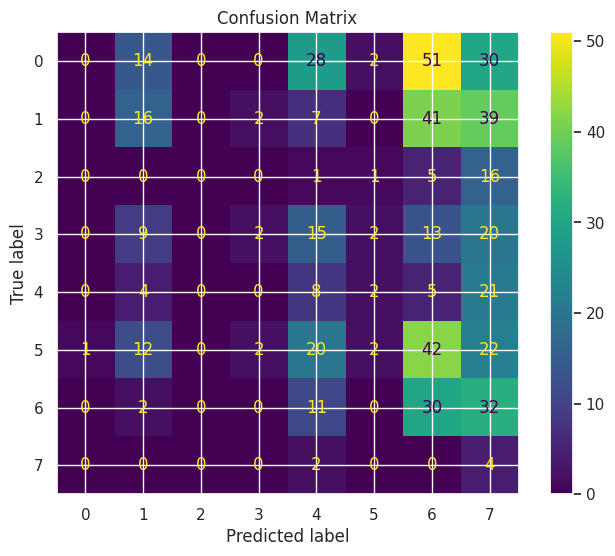

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_50_16
------------------------------
TRAIN
Accuracy: 0.3275
Precision: 0.3079
Recall: 0.3275
F1: 0.2807
Kappa: 0.1543
Error Rate: 0.6725

TEST
Accuracy: 0.2257
Precision: 0.1523
Recall: 0.2257
F1: 0.1609
Kappa: 0.0583
Error Rate: 0.7743
Gap (overfitting): 0.1017

CV
Mean: 0.3462
Std: 0.0280
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



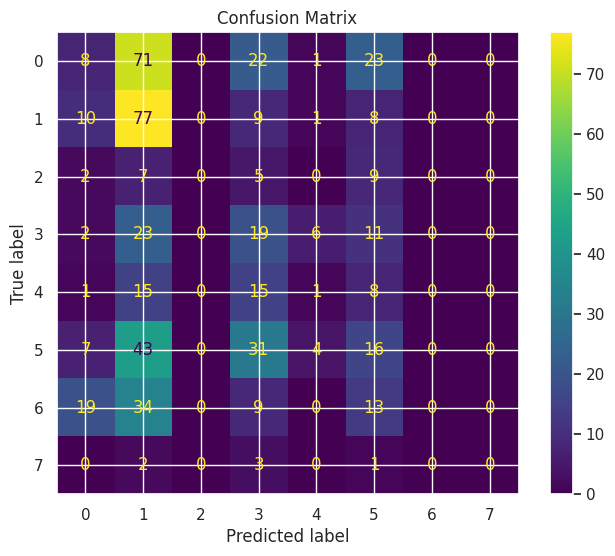

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_0
------------------------------
TRAIN
Accuracy: 0.3835
Precision: 0.3914
Recall: 0.3835
F1: 0.3536
Kappa: 0.2338
Error Rate: 0.6165

TEST
Accuracy: 0.0728
Precision: 0.2289
Recall: 0.0728
F1: 0.0816
Kappa: 0.0258
Error Rate: 0.9272
Gap (overfitting): 0.3107

CV
Mean: 0.3681
Std: 0.0128
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



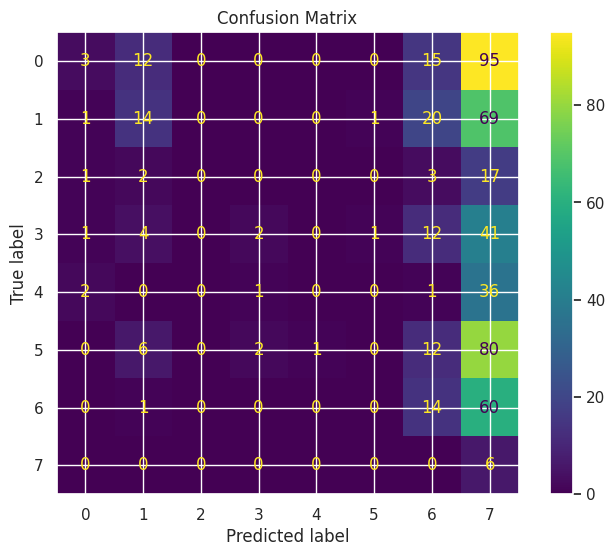

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: RNN_GRU_e-1
------------------------------
TRAIN
Accuracy: 0.3827
Precision: 0.3969
Recall: 0.3827
F1: 0.3463
Kappa: 0.2304
Error Rate: 0.6173

TEST
Accuracy: 0.0578
Precision: 0.3368
Recall: 0.0578
F1: 0.0642
Kappa: 0.0136
Error Rate: 0.9422
Gap (overfitting): 0.3249

CV
Mean: 0.3725
Std: 0.0148
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.1, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



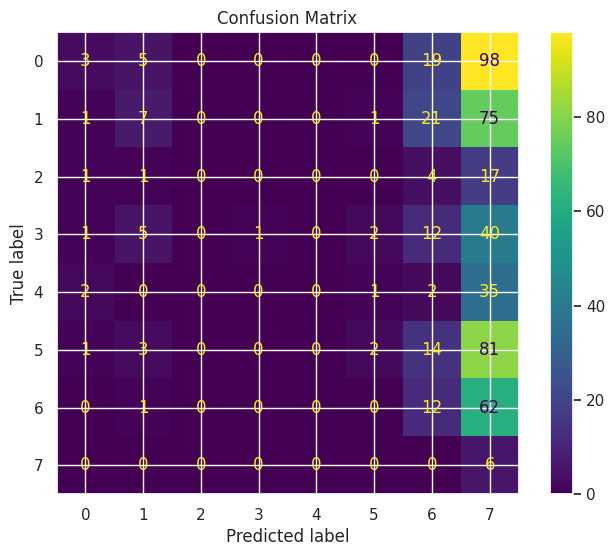

In [6]:
models_rnn_gru_f2 = {}


# ============================================================
# OTIMIZADORES
# ============================================================


models_rnn_gru_f2['RNN_GRU_adam'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f2['RNN_GRU_sgd'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f2['RNN_GRU_rmsprop'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='rmsprop', learning_rate=0.001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ARQUITETURAS
# ============================================================


# equivalente a hidden=30 (rnn=8, gru=8)
models_rnn_gru_f2['RNN_GRU_30'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# equivalente a hidden=50 (rnn=16, gru=16)
models_rnn_gru_f2['RNN_GR_50'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# 2 camadas RNN + 2 camadas GRU
models_rnn_gru_f2['RNN_GRU_50_16'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# REGULARIZAÇÃO
# ============================================================


models_rnn_gru_f2['RNN_GRU_0'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f2['RNN_GRU_e-1'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.1,
    gru_hidden=8, gru_layers=1, gru_dropout=0.1, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)

main(models_rnn_gru_f2, "rnn_gru_fase_2")



/tmp/ipykernel_4941/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30
------------------------------
TRAIN
Accuracy: 0.4227
Precision: 0.3549
Recall: 0.4227
F1: 0.3630
Kappa: 0.2880
Error Rate: 0.5773

TEST
Accuracy: 0.2015
Precision: 0.2064
Recall: 0.2015
F1: 0.1210
Kappa: 0.0238
Error Rate: 0.7985
Gap (overfitting): 0.2212

CV
Mean: 0.4224
Std: 0.0433
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



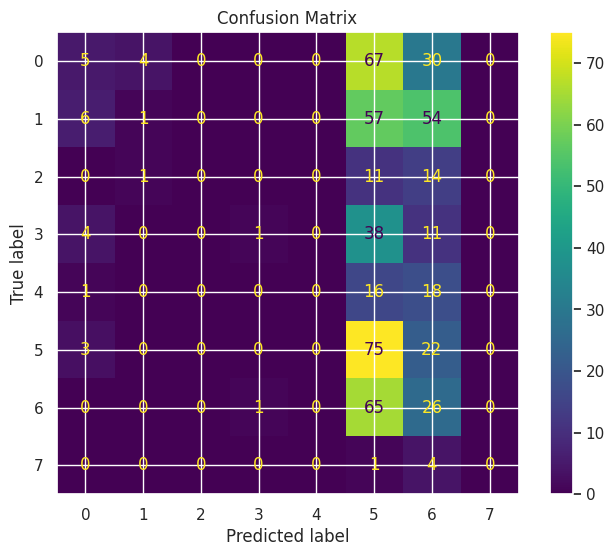

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_95
------------------------------
TRAIN
Accuracy: 0.5765
Precision: 0.5772
Recall: 0.5765
F1: 0.5621
Kappa: 0.4815
Error Rate: 0.4235

TEST
Accuracy: 0.1903
Precision: 0.1913
Recall: 0.1903
F1: 0.0919
Kappa: 0.0266
Error Rate: 0.8097
Gap (overfitting): 0.3862

CV
Mean: 0.5580
Std: 0.0438
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



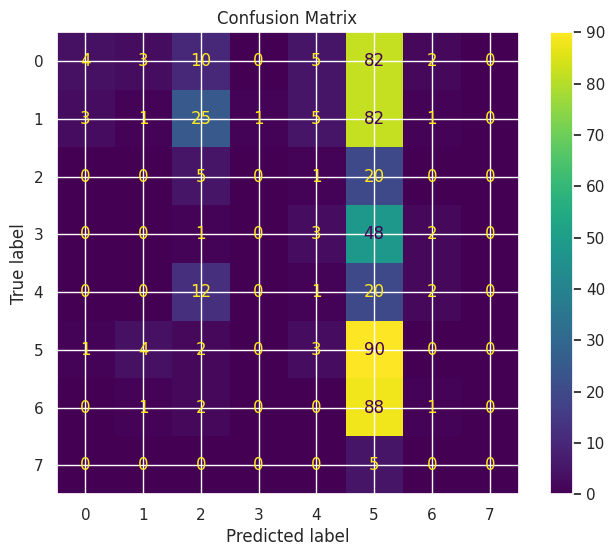

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50
------------------------------
TRAIN
Accuracy: 0.4524
Precision: 0.4499
Recall: 0.4524
F1: 0.4092
Kappa: 0.3264
Error Rate: 0.5476

TEST
Accuracy: 0.1511
Precision: 0.1236
Recall: 0.1511
F1: 0.1000
Kappa: -0.0129
Error Rate: 0.8489
Gap (overfitting): 0.3012

CV
Mean: 0.4459
Std: 0.0267
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



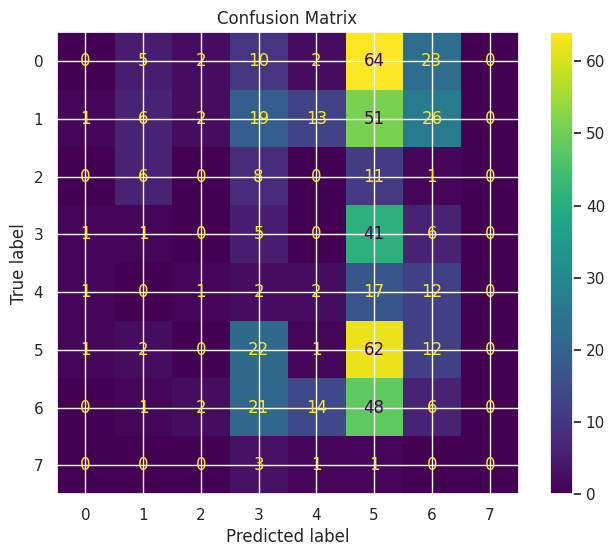

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_sgd95
------------------------------
TRAIN
Accuracy: 0.6613
Precision: 0.6748
Recall: 0.6613
F1: 0.6481
Kappa: 0.5865
Error Rate: 0.3387

TEST
Accuracy: 0.1455
Precision: 0.1272
Recall: 0.1455
F1: 0.0913
Kappa: 0.0305
Error Rate: 0.8545
Gap (overfitting): 0.5158

CV
Mean: 0.6409
Std: 0.0429
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



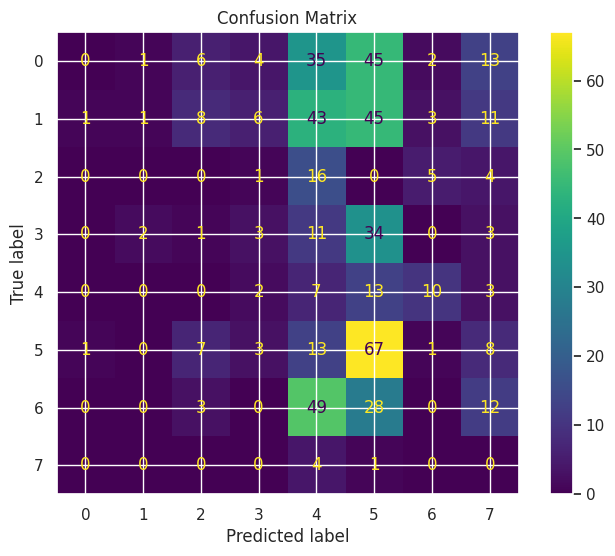

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16sgd
------------------------------
TRAIN
Accuracy: 0.2154
Precision: 0.0464
Recall: 0.2154
F1: 0.0763
Kappa: 0.0000
Error Rate: 0.7846

TEST
Accuracy: 0.2015
Precision: 0.1327
Recall: 0.2015
F1: 0.0729
Kappa: 0.0048
Error Rate: 0.7985
Gap (overfitting): 0.0139

CV
Mean: 0.2050
Std: 0.0084
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



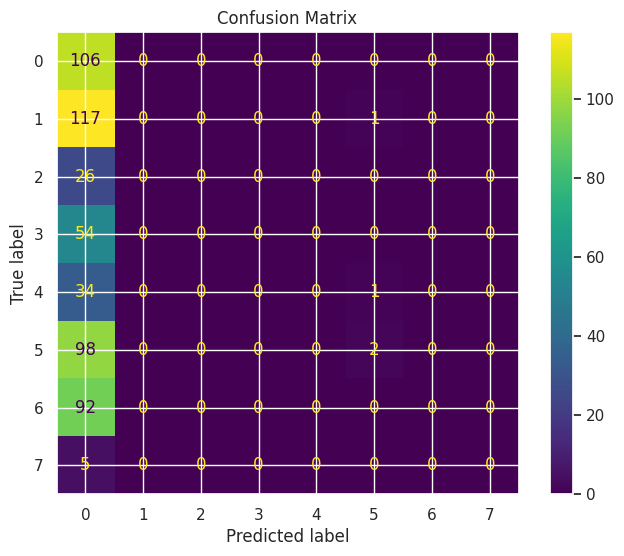

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16_sgd95
------------------------------
TRAIN
Accuracy: 0.3867
Precision: 0.3021
Recall: 0.3867
F1: 0.2905
Kappa: 0.2353
Error Rate: 0.6133

TEST
Accuracy: 0.2257
Precision: 0.1221
Recall: 0.2257
F1: 0.1575
Kappa: 0.0589
Error Rate: 0.7743
Gap (overfitting): 0.1610

CV
Mean: 0.3725
Std: 0.0242
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.95, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



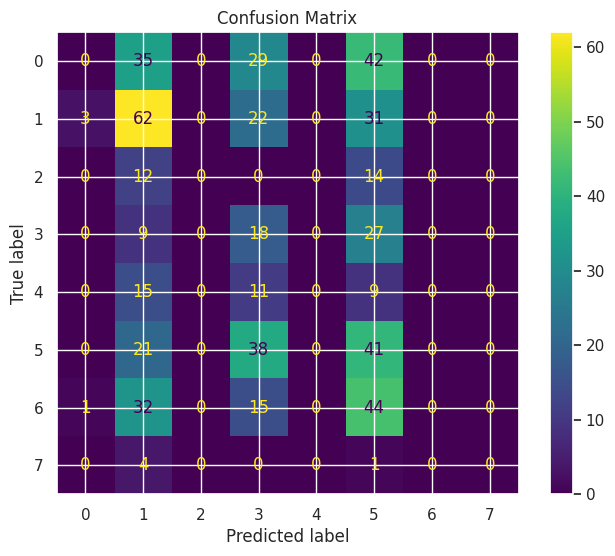

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_1e-4
------------------------------
TRAIN
Accuracy: 0.3659
Precision: 0.2647
Recall: 0.3659
F1: 0.2881
Kappa: 0.2160
Error Rate: 0.6341

TEST
Accuracy: 0.1418
Precision: 0.2152
Recall: 0.1418
F1: 0.0972
Kappa: 0.0081
Error Rate: 0.8582
Gap (overfitting): 0.2241

CV
Mean: 0.4375
Std: 0.0244
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.2, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



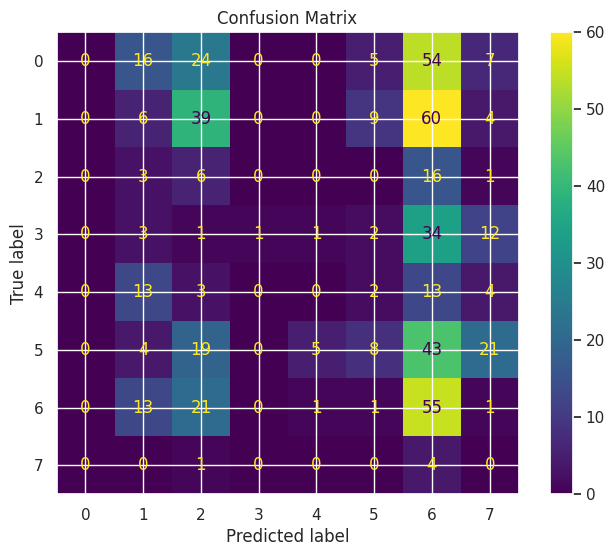

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_1e-4
------------------------------
TRAIN
Accuracy: 0.4604
Precision: 0.4599
Recall: 0.4604
F1: 0.4226
Kappa: 0.3379
Error Rate: 0.5396

TEST
Accuracy: 0.1007
Precision: 0.1765
Recall: 0.1007
F1: 0.0911
Kappa: 0.0164
Error Rate: 0.8993
Gap (overfitting): 0.3596

CV
Mean: 0.4387
Std: 0.0228
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 1, 'rnn_dropout': 0.2, 'gru_hidden': 16, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



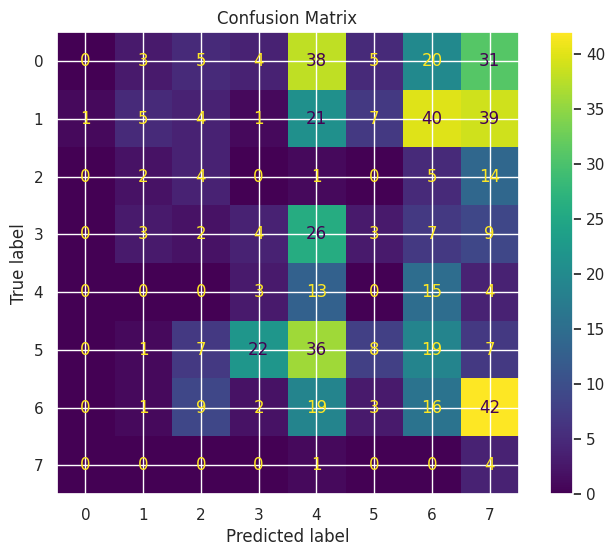

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_16_1e-4
------------------------------
TRAIN
Accuracy: 0.3203
Precision: 0.2377
Recall: 0.3203
F1: 0.2430
Kappa: 0.1624
Error Rate: 0.6797

TEST
Accuracy: 0.2034
Precision: 0.1227
Recall: 0.2034
F1: 0.1392
Kappa: 0.0628
Error Rate: 0.7966
Gap (overfitting): 0.1169

CV
Mean: 0.3793
Std: 0.0313
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.2, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.2, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'adam', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



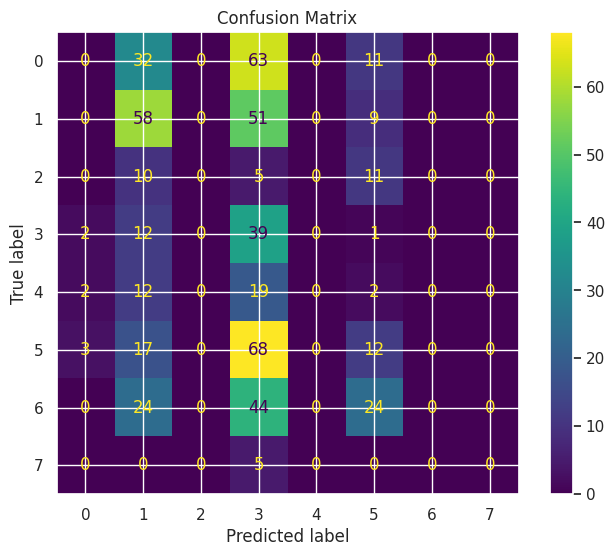

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd2
------------------------------
TRAIN
Accuracy: 0.4155
Precision: 0.3563
Recall: 0.4155
F1: 0.3559
Kappa: 0.2761
Error Rate: 0.5845

TEST
Accuracy: 0.2220
Precision: 0.2193
Recall: 0.2220
F1: 0.1446
Kappa: 0.0477
Error Rate: 0.7780
Gap (overfitting): 0.1935

CV
Mean: 0.4140
Std: 0.0396
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.2, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.2, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



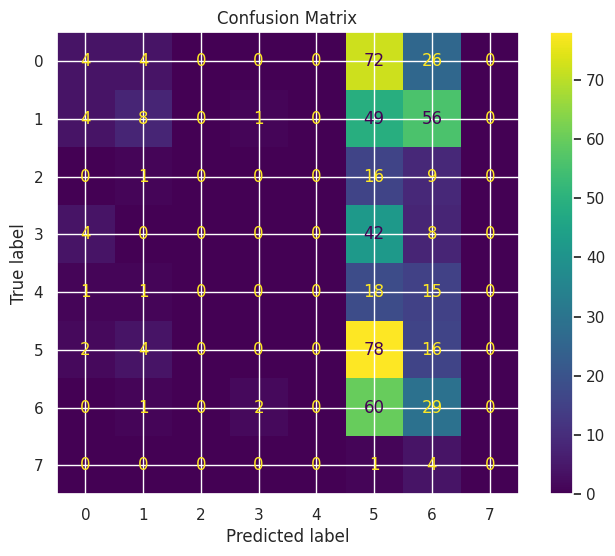

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgd3
------------------------------
TRAIN
Accuracy: 0.4083
Precision: 0.3548
Recall: 0.4083
F1: 0.3475
Kappa: 0.2663
Error Rate: 0.5917

TEST
Accuracy: 0.1940
Precision: 0.1934
Recall: 0.1940
F1: 0.1549
Kappa: 0.0188
Error Rate: 0.8060
Gap (overfitting): 0.2143

CV
Mean: 0.4073
Std: 0.0381
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.3, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.3, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



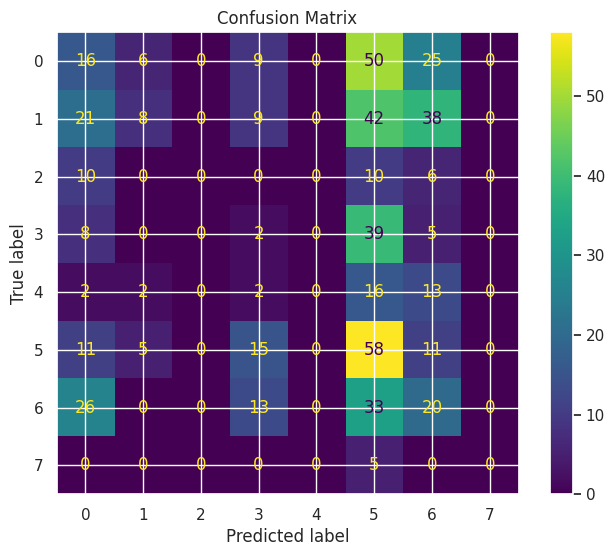

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_sgdlowLR
------------------------------
TRAIN
Accuracy: 0.2162
Precision: 0.1497
Recall: 0.2162
F1: 0.0780
Kappa: 0.0010
Error Rate: 0.7838

TEST
Accuracy: 0.2220
Precision: 0.1441
Recall: 0.2220
F1: 0.1280
Kappa: 0.0270
Error Rate: 0.7780
Gap (overfitting): -0.0058

CV
Mean: 0.2347
Std: 0.0288
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



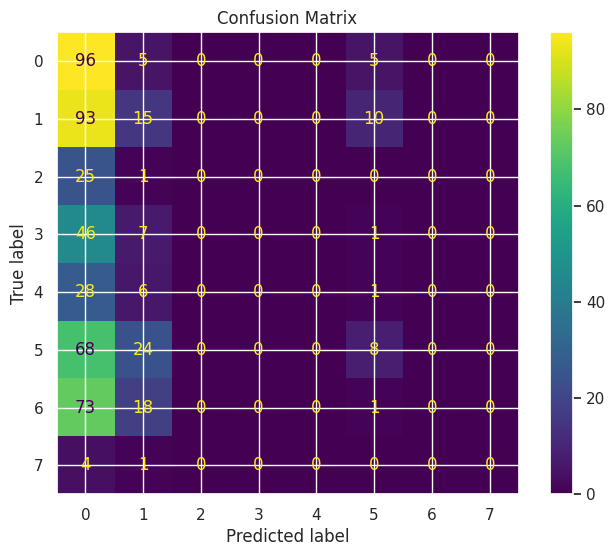

In [7]:
models_rnn_gru_f3 = {}


# ============================================================
# 🔥 BASE TOP (SGD)
# ============================================================


models_rnn_gru_f3['F2_30'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_30_95'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_50'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_50_sgd95'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_50_16sgd'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_50_16_sgd95'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.95, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# ⚖️ CONTROLE (ADAM)
# ============================================================


models_rnn_gru_f3['F2_30_1e-4'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.2,
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_50_1e-4'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=1, rnn_dropout=0.2,
    gru_hidden=16, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_50_16_1e-4'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.2,
    gru_hidden=16, gru_layers=2, gru_dropout=0.2, fc_hidden=(16,),
    solver='adam', learning_rate=0.0001, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 EXTRA: Regularização para SGD
# ============================================================


models_rnn_gru_f3['F2_30_sgd2'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.2,
    gru_hidden=8, gru_layers=1, gru_dropout=0.2, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_30_sgd3'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.3,
    gru_hidden=8, gru_layers=1, gru_dropout=0.3, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f3['F2_30_sgdlowLR'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


main(models_rnn_gru_f3, "rnn_gru_fase_3")



/tmp/ipykernel_4941/1652769159.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(re


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_31e-30_sgd
------------------------------
TRAIN
Accuracy: 0.4476
Precision: 0.3963
Recall: 0.4476
F1: 0.4021
Kappa: 0.3141
Error Rate: 0.5524

TEST
Accuracy: 0.2108
Precision: 0.0885
Recall: 0.2108
F1: 0.1001
Kappa: -0.0235
Error Rate: 0.7892
Gap (overfitting): 0.2367

CV
Mean: 0.4756
Std: 0.0091
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



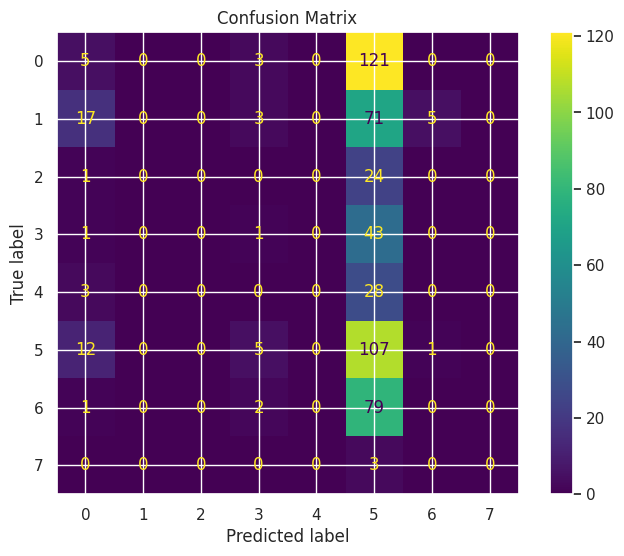

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_10_sgd
------------------------------
TRAIN
Accuracy: 0.2642
Precision: 0.1341
Recall: 0.2642
F1: 0.1571
Kappa: 0.0634
Error Rate: 0.7358

TEST
Accuracy: 0.2220
Precision: 0.1356
Recall: 0.2220
F1: 0.1033
Kappa: -0.0130
Error Rate: 0.7780
Gap (overfitting): 0.0422

CV
Mean: 0.2471
Std: 0.0285
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.0, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.0, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



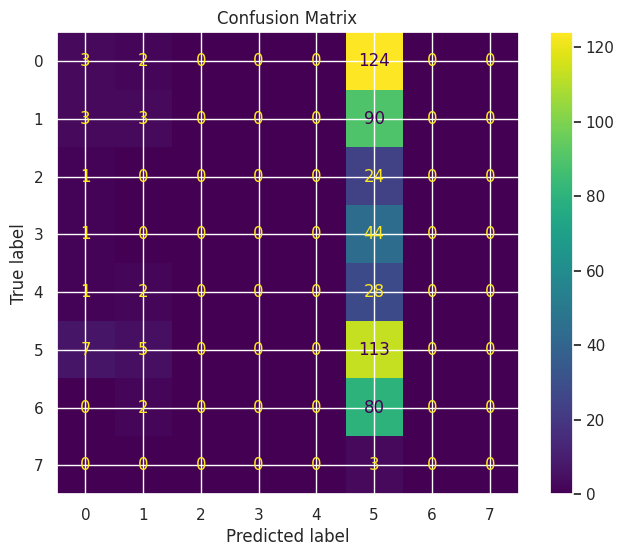

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_1_sgd
------------------------------
TRAIN
Accuracy: 0.4420
Precision: 0.3917
Recall: 0.4420
F1: 0.3969
Kappa: 0.3070
Error Rate: 0.5580

TEST
Accuracy: 0.2220
Precision: 0.2192
Recall: 0.2220
F1: 0.1326
Kappa: -0.0073
Error Rate: 0.7780
Gap (overfitting): 0.2199

CV
Mean: 0.4863
Std: 0.0185
------------------------------
Model params:
{'rnn_hidden': 8, 'rnn_layers': 1, 'rnn_dropout': 0.1, 'gru_hidden': 8, 'gru_layers': 1, 'gru_dropout': 0.1, 'fc_hidden': (), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



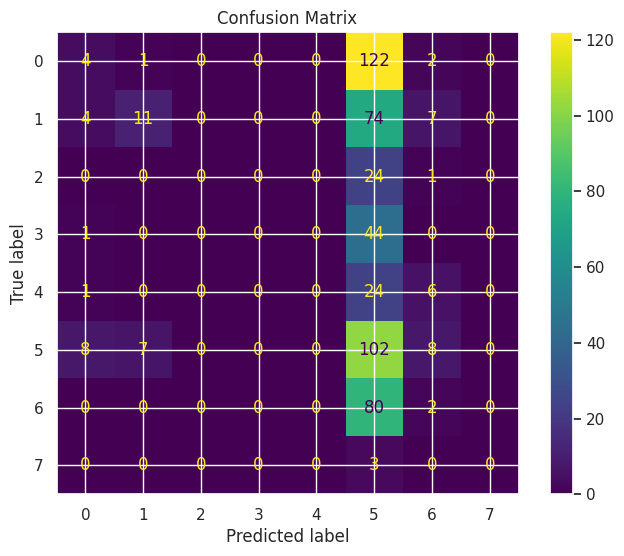

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_e-30_sgd
------------------------------
TRAIN
Accuracy: 0.2978
Precision: 0.1317
Recall: 0.2978
F1: 0.1814
Kappa: 0.1064
Error Rate: 0.7022

TEST
Accuracy: 0.2146
Precision: 0.1013
Recall: 0.2146
F1: 0.1353
Kappa: -0.0280
Error Rate: 0.7854
Gap (overfitting): 0.0833

CV
Mean: 0.3860
Std: 0.0293
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



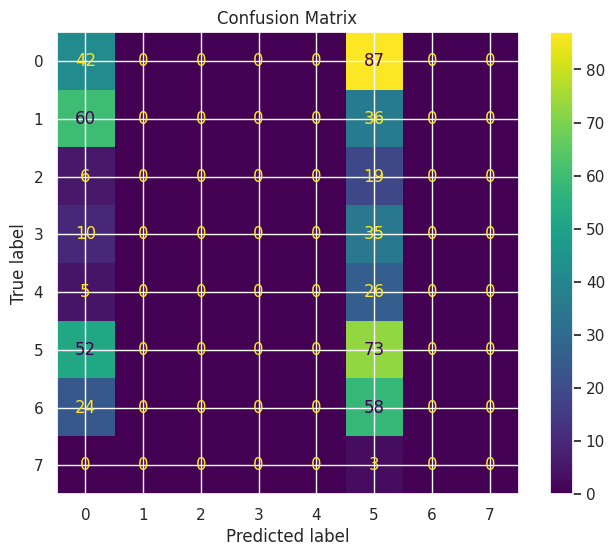

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50e-40_sgd
------------------------------
TRAIN
Accuracy: 0.2146
Precision: 0.0460
Recall: 0.2146
F1: 0.0758
Kappa: 0.0000
Error Rate: 0.7854

TEST
Accuracy: 0.2444
Precision: 0.1582
Recall: 0.2444
F1: 0.1042
Kappa: 0.0050
Error Rate: 0.7556
Gap (overfitting): -0.0298

CV
Mean: 0.2230
Std: 0.0101
------------------------------
Model params:
{'rnn_hidden': 16, 'rnn_layers': 2, 'rnn_dropout': 0.0, 'gru_hidden': 16, 'gru_layers': 2, 'gru_dropout': 0.0, 'fc_hidden': (16,), 'input_size': 21, 'output_size': 8, 'solver': 'sgd', 'learning_rate': 0.0001, 'momentum': 0.9, 'epochs': 500, 'batch_size': 32, 'random_state': 42, 'device': 'cpu'}



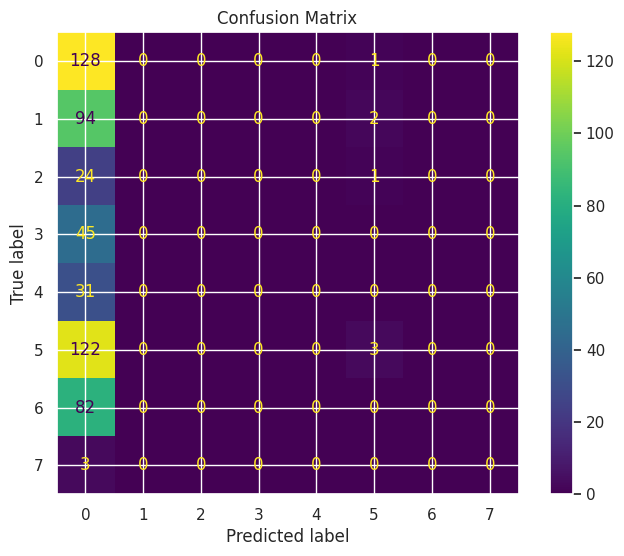

In [8]:
models_rnn_gru_f4 = {}


# ============================================================
# 🔥 SGD com arquitetura base (30)
# ============================================================


models_rnn_gru_f4['F3_31e-30_sgd'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f4['F3_30_10_sgd'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.0,
    gru_hidden=8, gru_layers=1, gru_dropout=0.0, fc_hidden=(),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


models_rnn_gru_f4['F3_30_1_sgd'] = RNN_GRU_Hybrid(
    rnn_hidden=8, rnn_layers=1, rnn_dropout=0.1,
    gru_hidden=8, gru_layers=1, gru_dropout=0.1, fc_hidden=(),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)


# ============================================================
# 🔥 SGD com arquitetura 50_16 (2 camadas)
# ============================================================


models_rnn_gru_f4['F3_50_e-30_sgd'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

models_rnn_gru_f4['F3_50e-40_sgd'] = RNN_GRU_Hybrid(
    rnn_hidden=16, rnn_layers=2, rnn_dropout=0.0,
    gru_hidden=16, gru_layers=2, gru_dropout=0.0, fc_hidden=(16,),
    solver='sgd', learning_rate=0.0001, momentum=0.9, epochs=500, batch_size=32, random_state=42
)

main(models_rnn_gru_f4, "rnn_gru_f4")
